# Certamen 2 — Reglas de asociación y sistema de recomendación
## ¿Qué ingrediente le falta a tu receta? Análisis de canasta sobre recetas de Food.com

**Grupo 2:** Lucas Torres Baeza · María Jesús Salinas
**Curso:** Aprendizaje no supervisado — Docente: Danilo Gómez Correa
**Repositorio:** `https://github.com/<usuario>/certamen2-grupo-2` · **Dashboard:** `https://<app>.streamlit.app`

Este notebook adapta la guía de clase (*Reglas de asociación y sistemas de recomendación en Python*)
a una base real de recetas. Sigue el flujo pedido en el enunciado:

`Base real → Transacciones → Exploración → Itemsets y reglas → Fisher + redundantes → Recomendador → HitRate@N vs. populares → Dashboard en GitHub`

**Contenido**
0. Preparación del entorno
1. Problema y base de datos
2. Limpieza y transacciones
3. Exploración
4. Itemsets y reglas
5. Fisher, redundantes y consulta dirigida
6. Recomendador
7. Evaluación offline
8. Hallazgos y recomendaciones
9. Exportación de CSV y armado del repositorio para GitHub

## 0. Preparación del entorno

En Colab hay que instalar `pyvis` (grafos interactivos) y fijar la versión de `mlxtend`
con la que se probó este notebook. **Después de instalar, reiniciar la sesión** (*Runtime → Restart session*)
solo si Colab lo pide.

In [1]:
# Instalación de librerías (solo necesario en Colab)
import sys
if "google.colab" in sys.modules:
    !pip install -q "mlxtend==0.23.4" pyvis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 756.0/756.0 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 35.5 MB/s eta 0:00:00


In [2]:
import os
import re
import ast
import time
import html
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

import plotly.express as px
import plotly.io as pio
from pyvis.network import Network
from IPython.display import HTML, display

# Configuración de visualización (igual que en la guía)
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_colwidth", 70)
plt.rcParams["figure.dpi"] = 110
pio.renderers.default = "colab" if "google.colab" in sys.modules else "notebook"

# Paleta de colores del curso
AZUL = "#0b1f45"
GRIS = "#52607a"
ROJO = "#c0392b"

# Semilla fija para que todo sea reproducible (muestra, partición y producto oculto)
SEMILLA = 42

import warnings
warnings.filterwarnings("ignore")

### Funciones auxiliares (de la guía)

`mlxtend` guarda antecedentes y consecuentes como `frozenset`. Estas funciones los dejan legibles
(`{flour} ⇒ {egg}`) y arman la tabla de reglas con las cinco medidas del curso.

In [3]:
def texto_itemset(itemset):
    # Convierte un frozenset en texto ordenado, por ejemplo: {egg, flour}
    return "{" + ", ".join(sorted(itemset)) + "}"


def tabla_reglas(reglas):
    # Tabla limpia con soporte, confianza, lift, leverage y convicción, ordenada por lift
    tabla = pd.DataFrame({
        "regla": reglas["antecedents"].apply(texto_itemset) + " ⇒ " + reglas["consequents"].apply(texto_itemset),
        "soporte": reglas["support"],
        "confianza": reglas["confidence"],
        "lift": reglas["lift"],
        "leverage": reglas["leverage"],
        "conviccion": reglas["conviction"],
    })
    return tabla.sort_values("lift", ascending=False).reset_index(drop=True)


def color_lift(valor, minimo, maximo):
    # Tono de rojo según el lift: más oscuro = asociación más fuerte
    escala = plt.get_cmap("Reds")
    proporcion = (valor - minimo) / (maximo - minimo) if maximo > minimo else 1
    return mcolors.to_hex(escala(0.25 + 0.75 * proporcion))


def mostrar_red(red, alto=650):
    # pyvis genera una página HTML completa; la mostramos en un iframe para que funcione en Colab
    pagina = red.generate_html()
    display(HTML(f'<iframe srcdoc="{html.escape(pagina)}" width="100%" height="{alto + 20}" '
                 f'style="border:1px solid #ddd; border-radius:6px"></iframe>'))

## 1. Problema y base de datos

| | |
|---|---|
| **Base** | *Food.com Recipes and User Interactions* (Kaggle, usuario `shuyangli94`) |
| **Enlace** | https://www.kaggle.com/datasets/shuyangli94/food-com-recipes-and-user-interactions |
| **Origen** | Recetas publicadas en Food.com (antes GeniusKitchen) entre 2000 y 2018. Recopilada por Majumder et al. (2019), *Generating Personalized Recipes from Historical User Preferences*, EMNLP. |
| **Licencia** | Publicada en Kaggle por los autores del paper; se usa solo con fines académicos y citando la fuente (Majumder et al., 2019). Los datos crudos no se redistribuyen en el repositorio. |
| **Archivos usados** | `RAW_recipes.csv` (231.637 recetas con su lista de ingredientes) e `ingr_map.pkl` (mapa de normalización de nombres de ingredientes). Los archivos de interacciones (valoraciones de usuarios) no se usan: sirven para filtrado colaborativo, no para análisis de canasta. |
| **Transacción** | Una **receta**. |
| **Ítem** | Un **ingrediente** (con su nombre normalizado). |

**Problema.** Una aplicación de recetas o un supermercado en línea quiere ayudar a quien está armando una
receta o su lista de compras: *"quienes usan estos ingredientes también usan…"*.

**Decisión que apoya el recomendador.** Sugerir los ingredientes que probablemente faltan en la lista
(venta cruzada en el supermercado en línea, o un recordatorio *"¿te falta la levadura?"* en la app),
mostrando el **motivo** (la regla) de cada sugerencia.

### 1.1 Carga de datos

El archivo `RAW_recipes.csv` pesa ~290 MB, por eso **no se sube a GitHub** (límite de 100 MB).
La celda siguiente busca los datos en este orden:

1. Carpeta `data_raw/` con `RAW_recipes.csv` e `ingr_map.pkl`.
2. El `archive.zip` descargado desde Kaggle (en la carpeta actual o en la carpeta de arriba).
   En Colab: subir `archive.zip` al panel *Archivos* antes de ejecutar.
3. Si no encuentra nada, intenta descargarlo con `kagglehub`.

In [4]:
CARPETA_DATOS = "data_raw"
ARCHIVOS = ["RAW_recipes.csv", "ingr_map.pkl"]


def preparar_datos():
    # 1) ¿Ya están los archivos descomprimidos?
    if all(os.path.exists(os.path.join(CARPETA_DATOS, a)) for a in ARCHIVOS):
        return CARPETA_DATOS
    # 2) ¿Está el zip de Kaggle? Extraemos solo los dos archivos que usamos
    for zip_ruta in ["archive.zip", "../archive.zip", "/content/archive.zip"]:
        if os.path.exists(zip_ruta):
            with zipfile.ZipFile(zip_ruta) as z:
                for a in ARCHIVOS:
                    z.extract(a, CARPETA_DATOS)
            return CARPETA_DATOS
    # 3) Descarga desde Kaggle
    import kagglehub
    return kagglehub.dataset_download("shuyangli94/food-com-recipes-and-user-interactions")


ruta = preparar_datos()

# Solo leemos las columnas necesarias: id, nombre y lista de ingredientes
recetas = pd.read_csv(os.path.join(ruta, "RAW_recipes.csv"), usecols=["id", "name", "ingredients", "n_ingredients"])
mapa = pd.read_pickle(os.path.join(ruta, "ingr_map.pkl"))

print(f"Recetas: {len(recetas):,}".replace(",", "."))
print(f"Entradas del mapa de ingredientes: {len(mapa):,}".replace(",", "."))
recetas.head()

100%|██████████| 267M/267M [00:04<00:00, 66.3MB/s]

Extracting files...


Recetas: 231.637
Entradas del mapa de ingredientes: 11.659


,name,id,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,"['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'bu...",7
1,a bit different breakfast pizza,31490,"['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt an...",6
2,all in the kitchen chili,112140,"['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste',...",13
3,alouette potatoes,59389,"['spreadable cheese with garlic and herbs', 'new potatoes', 'shall...",11
4,amish tomato ketchup for canning,44061,"['tomato juice', 'apple cider vinegar', 'sugar', 'salt', 'pepper',...",8


In [5]:
# La columna 'ingredients' viene como texto con forma de lista: "['salt', 'butter', ...]"
# ast.literal_eval la convierte en una lista real de Python
recetas["ingredients"] = recetas["ingredients"].apply(ast.literal_eval)
print("Ejemplo de receta:", recetas.loc[0, "name"])
print(recetas.loc[0, "ingredients"])

# El mapa traduce el nombre crudo (raw_ingr) a un nombre base (replaced)
mapa[["raw_ingr", "replaced"]].sample(8, random_state=SEMILLA)

Ejemplo de receta: arriba   baked winter squash mexican style
['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']


,raw_ingr,replaced
3858,low-fat turkey kielbasa,turkey kielbasa
5688,pork butterfly steaks,pork butterfly steak
8834,dried chilies,dried chily
9147,ground coriander,ground coriander
6398,cinnamon baking chips,cinnamon baking chip
8468,pasta,pastum
9559,butternut squash,butternut squash
8690,candy cane,candy cane


## 2. Limpieza y transacciones

### 2.1 Nulos, duplicados y registros inválidos

In [6]:
n_inicial = len(recetas)

# Nulos en las columnas que usamos
print("Nulos por columna:")
print(recetas[["id", "name", "ingredients"]].isna().sum().to_string())

# Duplicados: misma receta (id) o mismo nombre con exactamente los mismos ingredientes
recetas["clave"] = recetas["name"].astype(str) + "|" + recetas["ingredients"].apply(lambda x: "|".join(sorted(x)))
dup_id = recetas["id"].duplicated().sum()
dup_receta = recetas["clave"].duplicated().sum()
recetas = recetas.drop_duplicates("id").drop_duplicates("clave").drop(columns="clave")

# Registros inválidos: recetas con menos de 2 ingredientes no tienen asociaciones que buscar
invalidas = (recetas["ingredients"].apply(len) < 2).sum()
recetas = recetas[recetas["ingredients"].apply(len) >= 2].reset_index(drop=True)

print(f"\nIds duplicados: {dup_id} | recetas repetidas (nombre + ingredientes): {dup_receta}")
print(f"Recetas con menos de 2 ingredientes: {invalidas}")
print(f"Recetas después de la limpieza: {len(recetas):,} de {n_inicial:,}".replace(",", "."))

Nulos por columna:
id             0
name           1
ingredients    0

Ids duplicados: 0 | recetas repetidas (nombre + ingredientes): 17
Recetas con menos de 2 ingredientes: 25
Recetas después de la limpieza: 231.595 de 231.637


**Decisiones de limpieza**

| Problema | Qué encontramos | Decisión |
|---|---|---|
| Nulos | 1 receta sin `name`; 0 sin `ingredients` | Se conserva: el nombre no se usa para construir la transacción. |
| Duplicados | 0 ids repetidos; 17 recetas con mismo nombre e ingredientes | Se eliminan (contarían dos veces la misma canasta). |
| Registros inválidos | 25 recetas con menos de 2 ingredientes | Se eliminan: con un solo ítem no hay asociación posible. |
| Devoluciones / cantidades negativas | No aplica: la base registra **qué** ingredientes lleva la receta, no cantidades ni compras | La matriz es binaria (usa / no usa). |
| Ingredientes repetidos en la misma receta | Aparecen tras normalizar (`butter` y `unsalted butter`) | `drop_duplicates` en formato largo (sección 2.3). |


### 2.2 Normalización de nombres de ítems

El mismo ingrediente aparece escrito de muchas formas (*"large eggs"*, *"egg"*, *"eggs"*). Se normaliza en tres pasos:

1. **Mapa de la base (`ingr_map.pkl`)**: lleva 11.659 nombres crudos a ~8.000 nombres base.
2. **Corrección de errores del mapa**: el mapa se generó con reemplazos automáticos de texto que dañaron algunos nombres
   (`flour` quedó como `"flmy"`, `miniature` como `"ature"`, `spaghetti` como `"spaghettus"`). Se corrigen.
3. **Unificación de variantes evidentes** entre los ingredientes frecuentes: la forma (fresco, seco, molido) o
   la marca no cambian el ingrediente (`garlic clove` → `garlic`, `all-purpose flour` → `flour`,
   `kosher salt` → `salt`). Los ítems compuestos como `salt and pepper` se separan en dos ítems.

In [7]:
# Ítems compuestos que se separan en dos
SEPARAR = {
    "salt and pepper": ["salt", "pepper"], "salt & pepper": ["salt", "pepper"],
    "salt & ground black pepper": ["salt", "pepper"], "salt and black pepper": ["salt", "pepper"],
    "salt and fresh ground black pepper": ["salt", "pepper"], "salt & fresh ground pepper": ["salt", "pepper"],
}

# Variantes que se unifican (nombre del mapa → nombre final)
CORREGIR = {
    # errores del mapa (singularización automática)
    "spaghettus": "spaghetti", "pastum": "pasta", "black olife": "black olive", "olife": "olive",
    "asparagu": "asparagus", "molass": "molasses", "green chily": "green chili", "of fresh mint": "mint",
    # sal y pimienta
    "kosher salt": "salt", "sea salt": "salt", "coarse salt": "salt", "table salt": "salt",
    "black pepper": "pepper", "fresh ground black pepper": "pepper", "ground black pepper": "pepper",
    "fresh ground pepper": "pepper", "ground pepper": "pepper", "cracked black pepper": "pepper",
    "fresh coarse ground black pepper": "pepper", "black peppercorn": "pepper",
    # harina, azúcar, mantequilla, aceite
    "all-purpose flour": "flour", "plain flour": "flour",
    "granulated sugar": "sugar", "white sugar": "sugar", "caster sugar": "sugar",
    "confectioners' sugar": "powdered sugar", "icing sugar": "powdered sugar",
    "light brown sugar": "brown sugar", "dark brown sugar": "brown sugar",
    "unsalted butter": "butter",
    "oil": "vegetable oil", "cooking oil": "vegetable oil", "canola oil": "vegetable oil",
    # agua y hielo
    "boiling water": "water", "cold water": "water", "warm water": "water", "hot water": "water",
    "ice cube": "ice",
    # ajo, hierbas y especias (fresco / seco / molido = mismo ingrediente)
    "garlic clove": "garlic", "minced garlic clove": "garlic", "fresh garlic": "garlic",
    "vanilla extract": "vanilla", "pure vanilla extract": "vanilla",
    "ground cinnamon": "cinnamon", "ground nutmeg": "nutmeg", "ground cumin": "cumin",
    "ground clove": "clove", "whole clove": "clove", "ground allspice": "allspice",
    "ground coriander": "coriander", "ground turmeric": "turmeric", "ground cardamom": "cardamom",
    "fresh ginger": "ginger", "gingerroot": "ginger", "ground ginger": "ginger",
    "fresh parsley": "parsley", "flat leaf parsley": "parsley", "dried parsley": "parsley",
    "fresh cilantro": "cilantro", "fresh basil": "basil", "dried basil": "basil",
    "fresh basil leaf": "basil", "basil leaf": "basil", "dried thyme": "thyme", "fresh thyme": "thyme",
    "dried oregano": "oregano", "fresh oregano": "oregano", "fresh rosemary": "rosemary",
    "dried rosemary": "rosemary", "fresh chive": "chive", "fresh dill": "dill", "dill weed": "dill",
    "cayenne": "cayenne pepper", "crushed red pepper flake": "red pepper flake",
    "jalapeno pepper": "jalapeno",
    # jugos y ralladuras
    "fresh lemon juice": "lemon juice", "lemon, juice of": "lemon juice",
    "fresh lime juice": "lime juice", "lime, juice of": "lime juice",
    "lemon, zest of": "lemon zest", "lemon peel": "lemon zest", "orange rind": "orange zest",
    # caldos y lácteos
    "chicken stock": "chicken broth", "beef stock": "beef broth", "vegetable stock": "vegetable broth",
    "whipping cream": "heavy cream", "heavy whipping cream": "heavy cream",
    "half-and-half cream": "half-and-half",
    # verduras y frutas
    "green pepper": "green bell pepper", "sweet red pepper": "red bell pepper",
    "fresh mushroom": "mushroom", "sliced mushroom": "mushroom", "button mushroom": "mushroom",
    "plum tomato": "tomato", "roma tomato": "tomato",
    "fresh spinach": "spinach", "baby spinach": "spinach", "frozen chopped spinach": "spinach",
    "frozen spinach": "spinach", "fresh strawberry": "strawberry", "fresh blueberry": "blueberry",
    # otros
    "cocoa powder": "cocoa", "unsweetened cocoa powder": "cocoa",
    "dry breadcrumb": "breadcrumb", "rolled oat": "oat", "oatmeal": "oat",
}

mapa_dict = dict(zip(mapa["raw_ingr"], mapa["replaced"]))


def normalizar(nombre):
    # Devuelve una LISTA con el/los nombres normalizados de un ingrediente crudo
    nombre = nombre.strip().lower()
    base = mapa_dict.get(nombre, nombre)                  # paso 1: mapa de la base
    base = base.replace("flmy", "flour")                  # paso 2: errores del mapa
    base = re.sub(r"^ature ", "miniature ", base)
    if base in SEPARAR:                                   # paso 3: ítems compuestos
        return SEPARAR[base]
    return [CORREGIR.get(base, base)]                     # paso 3: variantes


for ejemplo in ["large eggs", "garlic cloves", "all-purpose flour", "kosher salt", "salt and pepper", "fresh parsley"]:
    print(f"{ejemplo:20s} → {normalizar(ejemplo)}")

large eggs           → ['large eggs']
garlic cloves        → ['garlic']
all-purpose flour    → ['flour']
kosher salt          → ['salt']
salt and pepper      → ['salt', 'pepper']
fresh parsley        → ['parsley']


### 2.3 Construcción de transacciones: de formato largo a canastas

Pasamos a **formato largo** (`id`, `item`): una fila por ingrediente de cada receta. Ahí se aplica la normalización,
se eliminan ingredientes repetidos dentro de una misma receta (por ejemplo, `butter` y `unsalted butter` pasan a ser
el mismo ítem) y luego se vuelve a **canastas** con `groupby`.

In [8]:
# Formato largo: una fila por (receta, ingrediente crudo)
largo = recetas[["id", "ingredients"]].explode("ingredients").rename(columns={"ingredients": "crudo"})

# Normalización (un ingrediente crudo puede generar 2 ítems, por eso se usa explode otra vez)
largo["item"] = largo["crudo"].apply(normalizar)
largo = largo.explode("item")[["id", "item"]]

# Sin ítems vacíos ni repetidos dentro de la misma receta
largo = largo[largo["item"].str.len() > 0].drop_duplicates()

print(f"Filas en formato largo: {len(largo):,}".replace(",", "."))
print(f"Ingredientes crudos distintos:      {recetas['ingredients'].explode().nunique():,}".replace(",", "."))
print(f"Ingredientes normalizados distintos: {largo['item'].nunique():,}".replace(",", "."))
largo.head(8)

Filas en formato largo: 2.106.566
Ingredientes crudos distintos:      14.942
Ingredientes normalizados distintos: 11.176


,id,item
0,137739,winter squash
0,137739,mexican seasoning
0,137739,mixed spice
0,137739,honey
0,137739,butter
0,137739,olive oil
0,137739,salt
1,31490,pizza crust


### 2.4 Muestra y catálogo de ítems

La base completa tiene más de 200 mil recetas y miles de ingredientes. Siguiendo las consideraciones técnicas del enunciado
(memoria y tiempo en Colab), trabajamos con:

- **Una muestra aleatoria de 30.000 recetas** (semilla fija). Supera con holgura el mínimo de 3.000 transacciones.
- **Un catálogo de ingredientes con soporte ≥ 0,5 %** en la muestra (presentes en al menos ~150 recetas).
  Un ingrediente con soporte menor **nunca** podría formar parte de un itemset frecuente con el soporte mínimo más bajo
  que probamos (0,005), por el **principio Apriori**: sacarlo no cambia ninguna regla y hace la matriz mucho más liviana.
  La cola larga se muestra en la sección 3.

Después del filtro se vuelven a descartar las recetas que quedaron con menos de 2 ingredientes.

In [9]:
TAMANO_MUESTRA = 30_000
SOPORTE_CATALOGO = 0.005

# 1) Muestra de recetas (semilla fija)
ids_muestra = recetas["id"].sample(TAMANO_MUESTRA, random_state=SEMILLA)
largo_muestra = largo[largo["id"].isin(ids_muestra)]

# 2) Soporte de cada ingrediente en la muestra = n° de recetas que lo usan / n° de recetas
soporte_muestra = largo_muestra.groupby("item")["id"].nunique() / TAMANO_MUESTRA
catalogo = soporte_muestra[soporte_muestra >= SOPORTE_CATALOGO].index
print(f"Ingredientes en la muestra: {len(soporte_muestra):,}".replace(",", "."))
print(f"Ingredientes con soporte ≥ {SOPORTE_CATALOGO}: {len(catalogo)}")

# 3) Formato largo → canastas con groupby (una lista de ingredientes por receta)
canastas = (largo_muestra[largo_muestra["item"].isin(catalogo)]
            .groupby("id")["item"].apply(list))
canastas = canastas[canastas.apply(len) >= 2]       # al menos 2 ítems por transacción
print(f"Transacciones finales: {len(canastas):,}".replace(",", "."))
canastas.head()

Ingredientes en la muestra: 6.373
Ingredientes con soporte ≥ 0.005: 222
Transacciones finales: 28.878


,item
id,
38,"[blueberry, sugar, lemon juice]"
40,"[sugar, lemon juice, ice]"
43,"[sugar, butter, cornstarch, salt, milk, egg yolk, vanilla, water, ..."
50,"[flour, sugar, baking powder, salt, egg, vanilla, almond extract, ..."
66,"[ketchup, red wine vinegar, brown sugar, onion, garlic, worcesters..."


In [10]:
# Matriz binaria transacción × ítem con TransactionEncoder (como en la guía)
codificador = TransactionEncoder()
matriz = codificador.fit_transform(canastas.tolist())
datos = pd.DataFrame(matriz, columns=codificador.columns_, index=canastas.index)

print(f"Matriz: {datos.shape[0]:,} recetas × {datos.shape[1]} ingredientes".replace(",", "."))
datos.iloc[:5, :10].astype(int)

Matriz: 28.878 recetas × 222 ingredientes


,allspice,almond,almond extract,apple,apple cider vinegar,applesauce,artificial sweetener,asparagus,avocado,bacon
id,,,,,,,,,,
38,0,0,0,0,0,0,0,0,0,0
40,0,0,0,0,0,0,0,0,0,0
43,0,0,0,0,0,0,0,0,0,0
50,0,0,1,0,0,0,0,0,0,0
66,0,0,0,0,0,0,0,0,0,0


## 3. Exploración

In [11]:
# Ítems por transacción, soporte de cada ítem, densidad y dispersión de la matriz
items_por_receta = datos.sum(axis=1)
soporte_item = datos.mean().sort_values(ascending=False)
densidad = datos.values.mean()
dispersion = 1 - densidad

resumen_datos = pd.Series({
    "Transacciones (recetas)": len(datos),
    "Ítems (ingredientes)": datos.shape[1],
    "Densidad": densidad,
    "Dispersión": dispersion,
    "Ítems por receta (promedio)": items_por_receta.mean(),
    "Ítems por receta (mediana)": items_por_receta.median(),
    "Ítems por receta (máximo)": items_por_receta.max(),
})
print(f"Densidad: {densidad:.2%}  |  Dispersión: {dispersion:.2%}")
resumen_datos.to_frame("valor")

Densidad: 3.23%  |  Dispersión: 96.77%


,valor
Transacciones (recetas),28878.000
Ítems (ingredientes),222.000
Densidad,0.032
Dispersión,0.968
Ítems por receta (promedio),7.162
Ítems por receta (mediana),7.000
Ítems por receta (máximo),25.000


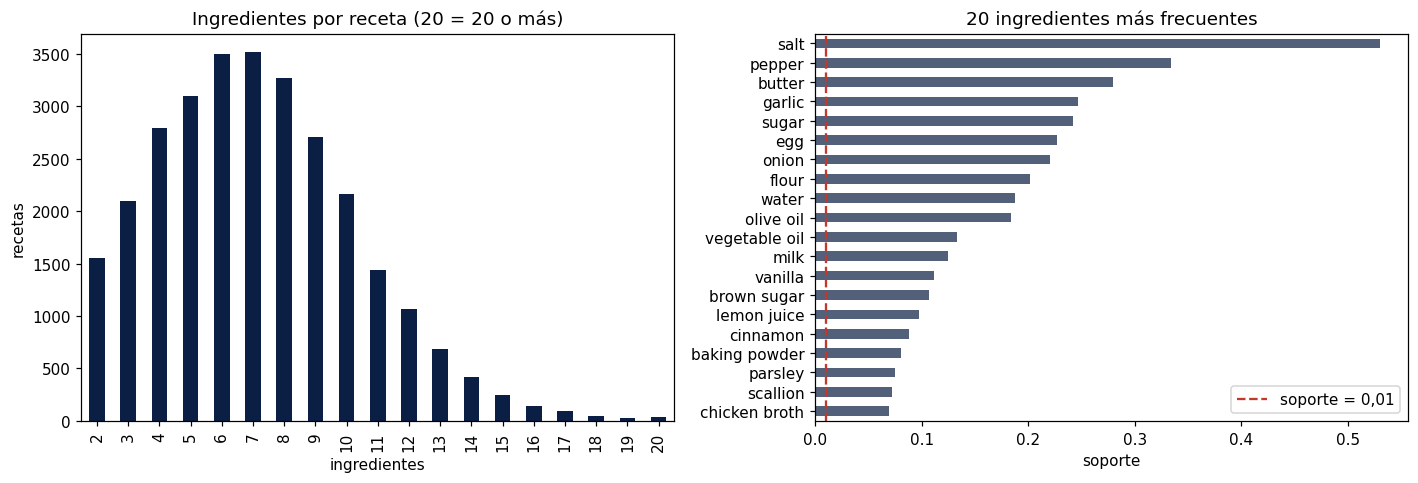

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Izquierda: cuántos ingredientes lleva cada receta (las de 20 o más se agrupan)
items_por_receta.clip(upper=20).value_counts().sort_index().plot.bar(ax=ax[0], color=AZUL)
ax[0].set_title("Ingredientes por receta (20 = 20 o más)")
ax[0].set_xlabel("ingredientes")
ax[0].set_ylabel("recetas")

# Derecha: los 20 ingredientes más frecuentes
soporte_item.head(20).sort_values().plot.barh(ax=ax[1], color=GRIS)
ax[1].axvline(0.01, color=ROJO, linestyle="--", label="soporte = 0,01")
ax[1].set_title("20 ingredientes más frecuentes")
ax[1].set_xlabel("soporte")
ax[1].legend()

plt.tight_layout()
plt.show()

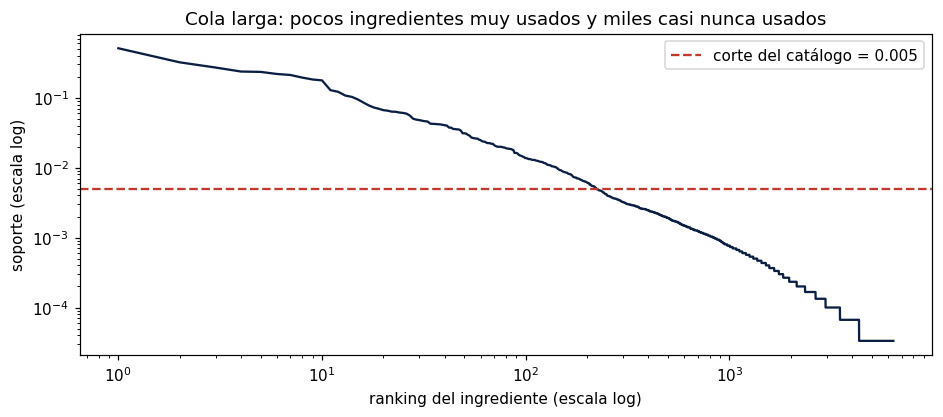

Ingredientes con soporte ≥ 0.05: 28
Ingredientes con soporte ≥ 0.02: 72
Ingredientes con soporte ≥ 0.01: 141
Ingredientes con soporte ≥ 0.005: 222


In [13]:
# Cola larga: soporte de TODOS los ingredientes de la muestra (antes del filtro), ordenados
fig, ax = plt.subplots(figsize=(10, 3.8))
orden_soporte = soporte_muestra.sort_values(ascending=False).values
ax.plot(range(1, len(orden_soporte) + 1), orden_soporte, color=AZUL)
ax.axhline(SOPORTE_CATALOGO, color=ROJO, linestyle="--", label=f"corte del catálogo = {SOPORTE_CATALOGO}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("ranking del ingrediente (escala log)")
ax.set_ylabel("soporte (escala log)")
ax.set_title("Cola larga: pocos ingredientes muy usados y miles casi nunca usados")
ax.legend()
plt.show()

for corte in [0.05, 0.02, 0.01, 0.005]:
    print(f"Ingredientes con soporte ≥ {corte}: {(soporte_muestra >= corte).sum()}")

**Matriz de co-ocurrencias.** Multiplicando la matriz por su transpuesta obtenemos cuántas recetas comparten cada par
de ingredientes. La diagonal es el conteo de cada ingrediente.

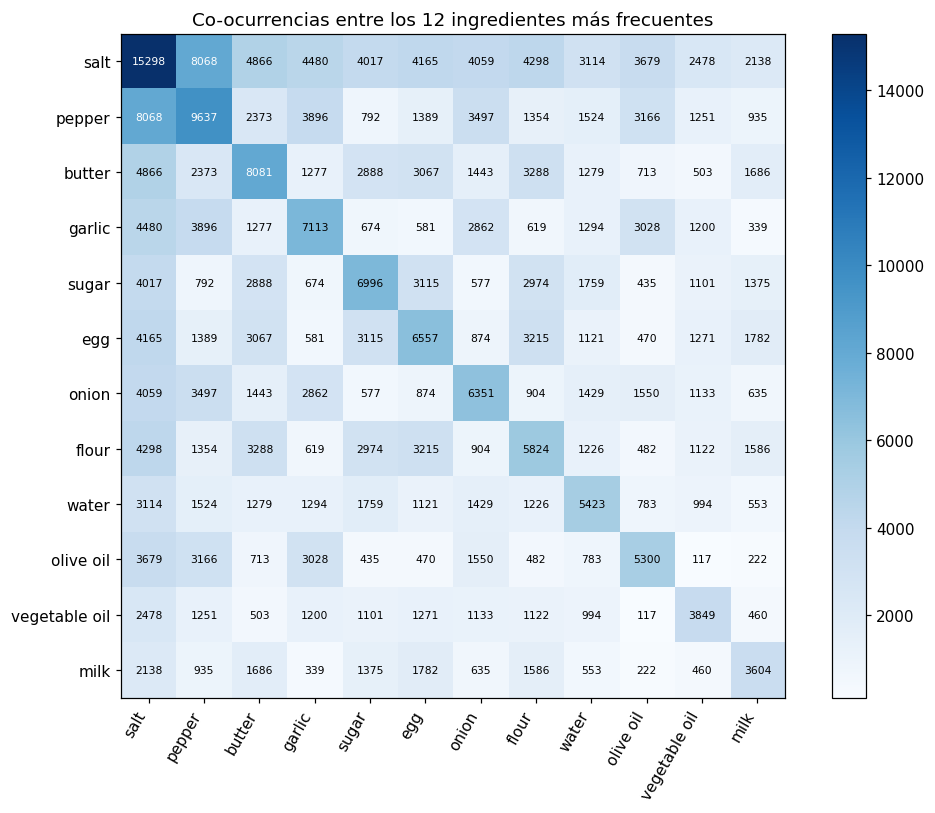

In [14]:
top12 = soporte_item.head(12).index
sub = datos[top12].astype(int)
coocurrencias = sub.T @ sub            # matriz 12 × 12 de conteos

fig, ax = plt.subplots(figsize=(9.5, 7.5))
imagen = ax.imshow(coocurrencias, cmap="Blues")
ax.set_xticks(range(12), top12, rotation=60, ha="right")
ax.set_yticks(range(12), top12)

# Número dentro de cada celda
limite = coocurrencias.values.max() / 2
for i in range(12):
    for j in range(12):
        valor = coocurrencias.iat[i, j]
        ax.text(j, i, valor, ha="center", va="center", fontsize=7,
                color="white" if valor > limite else "black")

ax.set_title("Co-ocurrencias entre los 12 ingredientes más frecuentes")
plt.colorbar(imagen, fraction=0.04)
plt.tight_layout()
plt.show()

**Hallazgos de la exploración (orientan la elección de umbrales)**

1. **Matriz muy dispersa:** la densidad es 3,2 % (dispersión 96,8 %). Cada receta usa en promedio 7,2 de los 222
   ingredientes del catálogo (mediana 7), así que hay asociaciones de sobra para buscar (≥ 2 ítems por transacción).
2. **Cola larga marcada:** de los 6.373 ingredientes de la muestra, solo 28 superan un soporte de 0,05 y 141 superan
   0,01. Un soporte mínimo de 0,05 dejaría casi solo ingredientes básicos; uno de 0,005 ya llega a 222 ingredientes.
   Por eso la tabla de sensibilidad prueba soportes entre **0,005 y 0,02**.
3. **Un ingrediente domina:** `salt` está en el **53 %** de las recetas y `pepper` en el 33 %. Igual que *whole milk*
   en *Groceries*, cualquier regla `X ⇒ {salt}` tendrá confianza alta aunque no exista asociación real: hay que
   mirar el **lift**.
4. **Dos "cocinas" en la tabla de co-ocurrencias:** `salt`–`pepper` (8.068 recetas), `garlic`–`olive oil`,
   `onion`–`pepper` forman el bloque **salado**; `sugar`–`egg`–`flour`–`butter` forman el bloque de **repostería**.
   Entre bloques casi no hay cruce (`olive oil`–`vegetable oil`: 117). Se espera que las reglas se agrupen en estos
   dos mundos.

## 4. Itemsets y reglas

### 4.1 Cálculo a mano de una regla

Calculamos **{onion powder} ⇒ {garlic powder}** directamente con las fórmulas y luego lo verificamos con `mlxtend`:

$$
sop = P(X \cap Z), \qquad conf = \frac{P(X \cap Z)}{P(X)}, \qquad lift = \frac{conf}{P(Z)}
$$

In [15]:
X, Z = "onion powder", "garlic powder"

n = len(datos)
con_x = datos[X].sum()                      # recetas con onion powder
con_z = datos[Z].sum()                      # recetas con garlic powder
con_ambos = (datos[X] & datos[Z]).sum()     # recetas con ambos

soporte = con_ambos / n
confianza = con_ambos / con_x
lift = confianza / (con_z / n)

print(f"n = {n} | con {X} = {con_x} | con {Z} = {con_z} | con ambos = {con_ambos}")
print(f"soporte   = {con_ambos}/{n} = {soporte:.4f}")
print(f"confianza = {con_ambos}/{con_x} = {confianza:.4f}")
print(f"lift      = {confianza:.4f} / ({con_z}/{n}) = {lift:.4f}")

n = 28878 | con onion powder = 448 | con garlic powder = 1372 | con ambos = 290
soporte   = 290/28878 = 0.0100
confianza = 290/448 = 0.6473
lift      = 0.6473 / (1372/28878) = 13.6249


In [16]:
# Verificación con mlxtend: itemsets del par y reglas sin umbral de confianza
par = apriori(datos[[X, Z]], min_support=0.0001, use_colnames=True)
verificacion = association_rules(par, metric="confidence", min_threshold=0)
verificacion = verificacion[(verificacion["antecedents"] == frozenset({X})) &
                            (verificacion["consequents"] == frozenset({Z}))]
tabla_reglas(verificacion)

,regla,soporte,confianza,lift,leverage,conviccion
0,{onion powder} ⇒ {garlic powder},0.010,0.647,13.625,0.009,2.701


**Verificación.** El cálculo a mano y `mlxtend` coinciden: soporte = 0,010, confianza = 0,647 y lift = 13,62.
En lenguaje de cocina: **el 65 % de las recetas que llevan cebolla en polvo también llevan ajo en polvo**, y eso es
**13,6 veces** más de lo que se esperaría si se usaran de forma independiente (solo el 4,8 % de las recetas lleva ajo
en polvo). Son los típicos condimentos secos que van juntos en aliños y mezclas para carnes.

### 4.2 Umbrales: tabla de sensibilidad

Número de itemsets frecuentes y de reglas para 3 valores de `min_support` y 3 de `min_threshold` (confianza).
Se usa FP-Growth con **`max_len=3`** (itemsets de hasta 3 ingredientes), como sugiere el enunciado para cuidar memoria
y tiempo; además, reglas más cortas son más fáciles de interpretar y de usar en el recomendador.

In [17]:
SOPORTES = [0.005, 0.01, 0.02]
CONFIANZAS = [0.3, 0.5, 0.7]
LARGO_MAX = 3

filas = []
itemsets_por_soporte = {}
for s in SOPORTES:
    inicio = time.perf_counter()
    frecuentes = fpgrowth(datos, min_support=s, use_colnames=True, max_len=LARGO_MAX)
    segundos = time.perf_counter() - inicio
    itemsets_por_soporte[s] = frecuentes
    for c in CONFIANZAS:
        r = association_rules(frecuentes, metric="confidence", min_threshold=c)
        filas.append({"min_support": s, "min_threshold": c, "itemsets": len(frecuentes),
                      "reglas": len(r), "lift mediano": r["lift"].median()})

sensibilidad = pd.DataFrame(filas)
sensibilidad

,min_support,min_threshold,itemsets,reglas,lift mediano
0,0.005,0.300,2645,3440,2.199
1,0.005,0.500,2645,2065,2.195
2,0.005,0.700,2645,679,2.215
3,0.010,0.300,1059,1475,2.157
4,0.010,0.500,1059,880,2.136
5,0.010,0.700,1059,294,2.136
6,0.020,0.300,444,680,2.192
7,0.020,0.500,444,407,2.136
8,0.020,0.700,444,148,2.187


In [18]:
# Misma tabla en formato cruzado: n° de reglas según soporte (filas) y confianza (columnas)
sensibilidad.pivot(index="min_support", columns="min_threshold", values="reglas")

min_threshold,0.300,0.500,0.700
min_support,,,
0.005,3440,2065,679
0.010,1475,880,294
0.020,680,407,148


**Elección de umbrales: $minsop = 0{,}01$ y $minconf = 0{,}5$.**

- Con soporte 0,005 aparecen **2.065–3.440 reglas**: demasiadas para interpretar y muchas apoyadas en ~150 recetas.
  Con 0,02 quedan solo 148–680 reglas y se pierden ingredientes que solo aparecen en 1–2 % de las recetas
  (especias como *nutmeg*, *clove* u *onion powder*), justo los que generan las asociaciones más interesantes.
- Con soporte **0,01** cada regla está respaldada por **al menos ~290 recetas** y el número de reglas es manejable.
- Confianza **0,5** exige que la regla acierte en al menos la mitad de las recetas que tienen el antecedente;
  con 0,7 quedan solo 294 reglas y casi todas apuntan a ingredientes muy comunes (`salt`, `egg`, `flour`).
- El **lift mediano casi no cambia** (≈ 2,1–2,2) entre combinaciones: los umbrales cambian *cuántas* reglas hay,
  no su fuerza típica. Por eso la fuerza se controla después con lift, Fisher y redundancia.

In [19]:
# Umbrales finales de la Parte 1
MIN_SOPORTE = 0.01
MIN_CONFIANZA = 0.5

### 4.3 Apriori vs. FP-Growth

Ambos algoritmos deben encontrar **exactamente los mismos itemsets**; solo cambia la forma de recorrer la base.

In [20]:
comparacion = []
for s in [0.02, MIN_SOPORTE]:
    inicio = time.perf_counter()
    it_apriori = apriori(datos, min_support=s, use_colnames=True, max_len=LARGO_MAX)
    t_apriori = time.perf_counter() - inicio

    inicio = time.perf_counter()
    it_fp = fpgrowth(datos, min_support=s, use_colnames=True, max_len=LARGO_MAX)
    t_fp = time.perf_counter() - inicio

    mismos = set(it_apriori["itemsets"]) == set(it_fp["itemsets"])
    comparacion.append({"min_support": s, "itemsets Apriori": len(it_apriori), "itemsets FP-Growth": len(it_fp),
                        "¿mismos itemsets?": mismos, "tiempo Apriori (s)": t_apriori, "tiempo FP-Growth (s)": t_fp})

pd.DataFrame(comparacion)

,min_support,itemsets Apriori,itemsets FP-Growth,¿mismos itemsets?,tiempo Apriori (s),tiempo FP-Growth (s)
0,0.020,444,444,True,1.886,36.790
1,0.010,1059,1059,True,8.170,88.863


**Resultado.** Ambos algoritmos encuentran **exactamente los mismos itemsets** (444 con soporte 0,02 y 1.059 con 0,01),
como dice la teoría. En tiempo, en esta base **Apriori fue más rápido**: ≈ 2 s vs. ≈ 39 s con soporte 0,02 y ≈ 8 s vs. ≈ 91 s con
soporte 0,01 (los segundos exactos cambian en cada ejecución, el orden de magnitud no).
La razón es práctica: con solo 222 ítems y `max_len = 3`, los candidatos de Apriori son pocos y `mlxtend` los cuenta
con operaciones vectorizadas de `numpy`, mientras su FP-Growth construye el árbol en Python puro. La ventaja de
FP-Growth aparece con **soportes bajos**: en nuestras pruebas con soporte 0,005, Apriori agotó la memoria del entorno
(7 GB) mientras FP-Growth terminó en ~90 s. Por eso se usa FP-Growth para la tabla de sensibilidad y el recomendador.

### 4.4 Tabla de reglas (`tabla_reglas`)

Reglas con $minsop = 0{,}01$ y $minconf = 0{,}5$, ordenadas por lift.

In [21]:
itemsets = itemsets_por_soporte[MIN_SOPORTE].copy()
itemsets["tamaño"] = itemsets["itemsets"].apply(len)
print("Itemsets frecuentes por tamaño:")
print(itemsets.groupby("tamaño")["itemsets"].count().to_string())

reglas = association_rules(itemsets.drop(columns="tamaño"), metric="confidence", min_threshold=MIN_CONFIANZA)
print(f"\nCantidad de reglas: {len(reglas)}")
tabla_reglas(reglas).head(15)

Itemsets frecuentes por tamaño:
tamaño
1    143
2    441
3    475

Cantidad de reglas: 880


,regla,soporte,confianza,lift,leverage,conviccion
0,{onion powder} ⇒ {garlic powder},0.010,0.647,13.625,0.009,2.701
1,"{baking powder, brown sugar} ⇒ {baking soda}",0.012,0.560,8.776,0.011,2.128
2,"{baking powder, cinnamon} ⇒ {baking soda}",0.013,0.558,8.736,0.011,2.116
3,{buttermilk} ⇒ {baking soda},0.010,0.529,8.292,0.009,1.989
4,"{yeast} ⇒ {sugar, water}",0.012,0.504,8.280,0.011,1.895
5,"{brown sugar, flour} ⇒ {baking soda}",0.021,0.518,8.118,0.019,1.943
6,"{brown sugar, vanilla} ⇒ {baking soda}",0.017,0.518,8.112,0.015,1.941
7,"{cinnamon, flour} ⇒ {baking soda}",0.020,0.513,8.033,0.017,1.921
8,"{nutmeg, sugar} ⇒ {cinnamon}",0.012,0.702,7.961,0.011,3.064
9,"{yeast} ⇒ {salt, water}",0.018,0.749,6.948,0.015,3.558


In [22]:
# Reglas simples (1 ingrediente ⇒ 1 ingrediente) con mayor lift: las más fáciles de explicar
simples = reglas[(reglas["antecedents"].apply(len) == 1) & (reglas["consequents"].apply(len) == 1)]
tabla_reglas(simples).head(10)

,regla,soporte,confianza,lift,leverage,conviccion
0,{onion powder} ⇒ {garlic powder},0.010,0.647,13.625,0.009,2.701
1,{buttermilk} ⇒ {baking soda},0.010,0.529,8.292,0.009,1.989
2,{clove} ⇒ {cinnamon},0.013,0.577,6.541,0.011,2.156
3,{baking soda} ⇒ {baking powder},0.032,0.503,6.250,0.027,1.850
4,{nutmeg} ⇒ {cinnamon},0.022,0.522,5.914,0.018,1.907
5,{cocoa} ⇒ {vanilla},0.013,0.651,5.830,0.011,2.543
6,{chocolate chip} ⇒ {vanilla},0.014,0.613,5.491,0.011,2.295
7,{baking soda} ⇒ {vanilla},0.036,0.558,5.003,0.029,2.011
8,{powdered sugar} ⇒ {vanilla},0.023,0.524,4.696,0.018,1.867
9,{yeast} ⇒ {water},0.019,0.790,4.207,0.014,3.869


**Interpretación de 5 reglas en el lenguaje de la cocina**

| Regla | Lectura |
|---|---|
| `{onion powder} ⇒ {garlic powder}` (conf 0,65; lift 13,6) | La asociación más fuerte de la base: los condimentos en polvo se usan juntos en aliños, *rubs* y salsas. Convicción 2,7: la regla falla 2,7 veces menos de lo que fallaría si fueran independientes. |
| `{buttermilk} ⇒ {baking soda}` (conf 0,53; lift 8,3) | Química de repostería: el suero de leche es ácido y se combina con bicarbonato para que la masa suba (*pancakes*, *biscuits*). |
| `{yeast} ⇒ {salt, water}` (conf 0,75; lift 6,9) | Receta básica de pan: 3 de cada 4 recetas con levadura llevan también agua y sal. Leverage 0,015: el par aparece en 1,5 % más de recetas que lo esperado. |
| `{nutmeg, sugar} ⇒ {cinnamon}` (conf 0,70; lift 8,0) | Mezcla de especias dulces (tartas de manzana, galletas). Su convicción (3,06) es de las más altas: es una regla muy confiable. |
| `{chocolate chip, egg} ⇒ {vanilla}` (conf 0,75; lift 6,7) | Galletas con chips de chocolate: 3 de cada 4 llevan vainilla, 6,7 veces más que el promedio. |

**Patrón general:** las reglas de mayor lift están dominadas por la **repostería** (polvos de hornear, especias dulces,
vainilla). Son recetas muy estandarizadas, con combinaciones casi fijas de ingredientes.

### 4.5 ¿Por qué no basta la confianza?

`salt` aparece en la mitad de las recetas (cumple el papel de *whole milk* en *Groceries*). Por eso casi cualquier
regla `X ⇒ {salt}` tiene una confianza "razonable" aunque no exista una asociación real. El **lift** lo corrige
comparando con $P(Z)$.

In [23]:
def evaluar_regla(antecedente, consecuente):
    # Soporte, confianza, P(consecuente) y lift de una regla simple {antecedente} ⇒ {consecuente}
    tiene_x = datos[antecedente]
    tiene_z = datos[consecuente]
    p_x = tiene_x.mean()
    p_z = tiene_z.mean()
    p_xz = (tiene_x & tiene_z).mean()
    return {
        "regla": f"{{{antecedente}}} ⇒ {{{consecuente}}}",
        "soporte": p_xz,
        "confianza": p_xz / p_x,
        "P(consecuente)": p_z,
        "lift": p_xz / (p_x * p_z),
    }


pd.DataFrame([
    evaluar_regla("sugar", "salt"),
    evaluar_regla("parmesan cheese", "salt"),
    evaluar_regla("yeast", "water"),
])

,regla,soporte,confianza,P(consecuente),lift
0,{sugar} ⇒ {salt},0.139,0.574,0.530,1.084
1,{parmesan cheese} ⇒ {salt},0.037,0.554,0.530,1.046
2,{yeast} ⇒ {water},0.019,0.790,0.188,4.207


**¿Cuál regla usaría la app?** `{sugar} ⇒ {salt}` tiene confianza 0,57 (más alta que muchas reglas útiles), pero
$P(salt) = 0{,}53$: la sal aparece en la mitad de las recetas *con o sin* azúcar, por eso el lift es apenas 1,08.
Lo mismo con `{parmesan cheese} ⇒ {salt}` (lift 1,05). Recomendar sal por estas reglas no aporta nada.
En cambio `{yeast} ⇒ {water}` tiene lift 4,2: el agua aparece en el 79 % de las recetas con levadura, frente al 19 %
del total. **Solo esta última refleja una asociación real**, y es la única que la app debería usar como motivo.

## 5. Fisher, redundantes y consulta dirigida

### 5.1 Significancia: test exacto de Fisher con corrección de Holm

Con cientos de reglas, algunas pueden aparecer **por azar**. Para cada regla se arma la tabla 2×2 y se aplica
el test de Fisher unilateral (¿$X$ aumenta la probabilidad de $Z$?). Como se hacen muchas pruebas a la vez,
los p-valores se corrigen con **Holm** ($\alpha = 0{,}01$).

|  | Tiene Z | No tiene Z |
|---|---|---|
| **Tiene X** | a | b |
| **No tiene X** | c | d |

In [24]:
def p_valor_fisher(antecedente, consecuente, matriz=datos):
    # Tabla 2×2 de la regla y test de Fisher unilateral
    tiene_x = matriz[list(antecedente)].all(axis=1)
    tiene_z = matriz[list(consecuente)].all(axis=1)

    a = (tiene_x & tiene_z).sum()
    b = (tiene_x & ~tiene_z).sum()
    c = (~tiene_x & tiene_z).sum()
    d = (~tiene_x & ~tiene_z).sum()

    _, p = fisher_exact([[a, b], [c, d]], alternative="greater")
    return p


reglas["p_valor"] = [p_valor_fisher(x, z) for x, z in zip(reglas["antecedents"], reglas["consequents"])]

# Corrección de Holm por comparaciones múltiples
reglas["significativa"], reglas["p_ajustado"], _, _ = multipletests(reglas["p_valor"], alpha=0.01, method="holm")

print(f"Reglas significativas: {reglas['significativa'].sum()} de {len(reglas)}")

# Las reglas que NO sobreviven (las de menor lift)
no_signif = reglas[~reglas["significativa"]]
pd.DataFrame({
    "regla": no_signif["antecedents"].apply(texto_itemset) + " ⇒ " + no_signif["consequents"].apply(texto_itemset),
    "confianza": no_signif["confidence"],
    "lift": no_signif["lift"],
    "p_ajustado": no_signif["p_ajustado"].apply(lambda p: f"{p:.1e}"),
}).sort_values("lift").reset_index(drop=True).head(10)

Reglas significativas: 848 de 880


,regla,confianza,lift,p_ajustado
0,{sour cream} ⇒ {salt},0.502,0.947,1.0e+00
1,{sausage} ⇒ {salt},0.510,0.962,1.0e+00
2,"{butter, powdered sugar} ⇒ {salt}",0.510,0.963,1.0e+00
3,"{lemon juice, sugar} ⇒ {salt}",0.512,0.967,1.0e+00
4,{ginger} ⇒ {salt},0.513,0.968,1.0e+00
5,{scallion} ⇒ {salt},0.513,0.969,1.0e+00
6,{margarine} ⇒ {salt},0.515,0.973,1.0e+00
7,{heavy cream} ⇒ {salt},0.522,0.985,1.0e+00
8,{bacon} ⇒ {salt},0.526,0.992,1.0e+00
9,"{garlic, scallion} ⇒ {salt}",0.531,1.002,1.0e+00


**¿Cuántas reglas sobreviven?** **848 de 880** (96 %). Las 32 que no son significativas son **todas del tipo
`X ⇒ {salt}`** con lift entre 0,95 y 1,14 (por ejemplo `{sour cream} ⇒ {salt}`, lift 0,95): cumplían la confianza mínima solo
porque la sal está en la mitad de las recetas. El test de Fisher con Holm las descarta de forma objetiva, sin elegir
un corte de lift arbitrario. Que sobrevivan tantas se explica por el tamaño de la muestra (28.878 recetas): con
tantos datos, incluso asociaciones moderadas son estadísticamente significativas, por eso además se revisa el lift.

### 5.2 Reglas redundantes

$X \Rightarrow Z$ es **redundante** si existe una regla más simple $X' \Rightarrow Z$, con $X' \subset X$,
que tiene **igual o mayor confianza**: agregar ingredientes al antecedente no aporta información nueva.

In [25]:
def marcar_redundantes(reglas):
    # Para cada regla, buscamos otra con el mismo consecuente y un antecedente más pequeño
    # (subconjunto estricto) que tenga confianza igual o mayor
    redundante = []
    for _, regla in reglas.iterrows():
        mismas_z = reglas[reglas["consequents"] == regla["consequents"]]
        mas_simples = mismas_z[mismas_z["antecedents"].apply(lambda x: x < regla["antecedents"])]
        redundante.append((mas_simples["confidence"] >= regla["confidence"]).any())
    return np.array(redundante)


reglas["redundante"] = marcar_redundantes(reglas)
print(f"Reglas redundantes: {reglas['redundante'].sum()} de {len(reglas)}")

# Ejemplo: una regla redundante y la regla más simple que la explica
ejemplo = reglas[reglas["redundante"]].sort_values("lift", ascending=False).iloc[0]
mas_simple = reglas[(reglas["consequents"] == ejemplo["consequents"]) &
                    (reglas["antecedents"].apply(lambda x: x < ejemplo["antecedents"]))].sort_values(
                        "confidence", ascending=False).iloc[0]
print(f"\nRedundante: {texto_itemset(ejemplo['antecedents'])} ⇒ {texto_itemset(ejemplo['consequents'])}"
      f"  (conf = {ejemplo['confidence']:.3f})")
print(f"Más simple: {texto_itemset(mas_simple['antecedents'])} ⇒ {texto_itemset(mas_simple['consequents'])}"
      f"  (conf = {mas_simple['confidence']:.3f})")

Reglas redundantes: 70 de 880

Redundante: {nutmeg, salt} ⇒ {cinnamon}  (conf = 0.507)
Más simple: {nutmeg} ⇒ {cinnamon}  (conf = 0.522)


In [26]:
# Reglas finales de la Parte 1: significativas y no redundantes
reglas_finales = reglas[reglas["significativa"] & ~reglas["redundante"]].reset_index(drop=True)

embudo = pd.DataFrame({
    "etapa": ["Reglas minadas (sop ≥ 0,01; conf ≥ 0,5)", "Significativas (Fisher + Holm)", "Significativas y no redundantes"],
    "reglas": [len(reglas), reglas["significativa"].sum(), len(reglas_finales)],
})
display(embudo)
tabla_reglas(reglas_finales).head(15)

,etapa,reglas
0,"Reglas minadas (sop ≥ 0,01; conf ≥ 0,5)",880
1,Significativas (Fisher + Holm),848
2,Significativas y no redundantes,785


,regla,soporte,confianza,lift,leverage,conviccion
0,{onion powder} ⇒ {garlic powder},0.010,0.647,13.625,0.009,2.701
1,"{baking powder, brown sugar} ⇒ {baking soda}",0.012,0.560,8.776,0.011,2.128
2,"{baking powder, cinnamon} ⇒ {baking soda}",0.013,0.558,8.736,0.011,2.116
3,{buttermilk} ⇒ {baking soda},0.010,0.529,8.292,0.009,1.989
4,"{yeast} ⇒ {sugar, water}",0.012,0.504,8.280,0.011,1.895
5,"{brown sugar, flour} ⇒ {baking soda}",0.021,0.518,8.118,0.019,1.943
6,"{brown sugar, vanilla} ⇒ {baking soda}",0.017,0.518,8.112,0.015,1.941
7,"{cinnamon, flour} ⇒ {baking soda}",0.020,0.513,8.033,0.017,1.921
8,"{nutmeg, sugar} ⇒ {cinnamon}",0.012,0.702,7.961,0.011,3.064
9,"{yeast} ⇒ {salt, water}",0.018,0.749,6.948,0.015,3.558


**Redundancia.** **70 de 880 reglas son redundantes.** Ejemplo: `{nutmeg, salt} ⇒ {cinnamon}` (conf 0,507) no aporta
nada frente a `{nutmeg} ⇒ {cinnamon}` (conf 0,522): agregar la sal al antecedente no aumenta la confianza, porque la sal
está en casi todas partes. Tras Fisher y redundancia quedan **785 reglas finales**, que son las que se interpretan y
se publican en el dashboard.

### 5.3 Consulta dirigida: ¿qué anticipa el uso de queso parmesano?

Fijamos el **consecuente** que nos interesa y vemos qué ingredientes lo anticipan
(en R: `appearance = list(rhs = ...)`). Para tener más candidatos se usan los itemsets con soporte 0,005 y
confianza ≥ 0,2.

In [27]:
OBJETIVO = "parmesan cheese"

reglas_objetivo = association_rules(itemsets_por_soporte[0.005], metric="confidence", min_threshold=0.2)
reglas_objetivo = reglas_objetivo[reglas_objetivo["consequents"] == frozenset({OBJETIVO})]
print(f"Reglas con consecuente {{{OBJETIVO}}}: {len(reglas_objetivo)}  |  P({OBJETIVO}) = {soporte_item[OBJETIVO]:.3f}")
tabla_reglas(reglas_objetivo).head(10)

Reglas con consecuente {parmesan cheese}: 13  |  P(parmesan cheese) = 0.068


,regla,soporte,confianza,lift,leverage,conviccion
0,"{garlic, mozzarella} ⇒ {parmesan cheese}",0.005,0.514,7.611,0.004,1.919
1,"{mozzarella, pepper} ⇒ {parmesan cheese}",0.005,0.450,6.663,0.005,1.696
2,"{mozzarella, salt} ⇒ {parmesan cheese}",0.006,0.439,6.503,0.005,1.663
3,{mozzarella} ⇒ {parmesan cheese},0.012,0.426,6.299,0.010,1.623
4,"{basil, garlic} ⇒ {parmesan cheese}",0.009,0.304,4.505,0.007,1.340
5,"{basil, olive oil} ⇒ {parmesan cheese}",0.008,0.304,4.502,0.006,1.340
6,"{basil, onion} ⇒ {parmesan cheese}",0.005,0.292,4.316,0.004,1.316
7,"{basil, salt} ⇒ {parmesan cheese}",0.009,0.276,4.087,0.007,1.288
8,{basil} ⇒ {parmesan cheese},0.014,0.271,4.005,0.010,1.278
9,{spinach} ⇒ {parmesan cheese},0.007,0.270,4.000,0.005,1.278


**¿Qué anticipa el queso parmesano?** Solo el 6,8 % de las recetas lo usa, pero hay **13 reglas** que lo anticipan.
Las más fuertes son de **cocina italiana**: `{garlic, mozzarella} ⇒ {parmesan cheese}` (conf 0,51; lift 7,6) y
`{mozzarella} ⇒ {parmesan cheese}` (lift 6,3), típicas de lasañas y pizzas; luego `{basil, garlic}` y
`{basil, olive oil}` (lift ≈ 4,5), base de pestos y salsas, y `{spinach}` (lift 4,0). **Uso:** si alguien agrega
mozzarella a su lista, la app o el supermercado en línea puede sugerir parmesano con un motivo claro.

### 5.4 Visualización

**a) Dispersión soporte–confianza coloreada por lift** (Plotly, interactiva: pasar el mouse sobre cada punto).

In [28]:
dispersion_reglas = tabla_reglas(reglas_finales)

figura = px.scatter(dispersion_reglas, x="soporte", y="confianza", color="lift",
                    hover_name="regla", hover_data={"soporte": ":.4f", "confianza": ":.3f", "lift": ":.2f"},
                    color_continuous_scale="Reds", height=500,
                    title=f"{len(dispersion_reglas)} reglas significativas y no redundantes (minsop = 0,01; minconf = 0,5)")
figura.update_traces(marker=dict(size=7, line=dict(width=0.3, color="white")))
figura.show()

**b) Grafo de reglas** (pyvis). Cuadros azules: ingredientes. Círculos rojos: reglas (tamaño = soporte; color = lift).
Las flechas van del antecedente a la regla y de la regla al consecuente. Se muestran las 30 reglas de mayor lift
para que el grafo sea legible.

In [29]:
def grafo_reglas(reglas, alto=650):
    red = Network(height=f"{alto}px", width="100%", directed=True, cdn_resources="remote")
    lift_min, lift_max = reglas["lift"].min(), reglas["lift"].max()
    soporte_max = reglas["support"].max()

    for i, regla in reglas.reset_index(drop=True).iterrows():
        nombre = f"regla {i + 1}"
        detalle = (f"{texto_itemset(regla['antecedents'])} ⇒ {texto_itemset(regla['consequents'])}\n"
                   f"soporte:   {regla['support']:.3f}\n"
                   f"confianza: {regla['confidence']:.3f}\n"
                   f"lift:      {regla['lift']:.2f}")

        # Nodo de la regla
        red.add_node(nombre, label=" ", title=detalle, shape="dot",
                     size=10 + 25 * regla["support"] / soporte_max,
                     color=color_lift(regla["lift"], lift_min, lift_max))

        # Nodos de ingredientes y flechas
        for item in regla["antecedents"] | regla["consequents"]:
            red.add_node(item, label=item, shape="box", color="#e6e9ef",
                         font={"color": AZUL, "size": 18}, title=f"soporte: {soporte_item[item]:.3f}")
        for item in regla["antecedents"]:
            red.add_edge(item, nombre, color=GRIS)
        for item in regla["consequents"]:
            red.add_edge(nombre, item, color=GRIS)

    red.repulsion(node_distance=140, spring_length=120)
    return red


mostrar_red(grafo_reglas(reglas_finales.sort_values("lift", ascending=False).head(30)))

**c) Mapa de flujo ingrediente → ingrediente.** Cada flecha es una regla simple $\{A\} \Rightarrow \{B\}$.
Grosor = confianza; color = lift; tamaño del nodo = soporte.

In [30]:
# Reglas ingrediente → ingrediente (itemsets de tamaño 2 como máximo)
pares = fpgrowth(datos, min_support=0.005, use_colnames=True, max_len=2)
reglas_pares = association_rules(pares, metric="confidence", min_threshold=0.15)
reglas_pares["desde"] = reglas_pares["antecedents"].apply(lambda x: next(iter(x)))
reglas_pares["hacia"] = reglas_pares["consequents"].apply(lambda x: next(iter(x)))
reglas_pares = reglas_pares[reglas_pares["lift"] > 1.2].reset_index(drop=True)
print(f"Reglas ingrediente → ingrediente: {len(reglas_pares)} entre {reglas_pares['desde'].nunique()} ingredientes")


def mapa_flujo(reglas_pares, lift_minimo=4.0, alto=700):
    seleccion = reglas_pares[reglas_pares["lift"] >= lift_minimo]
    red = Network(height=f"{alto}px", width="100%", directed=True, cdn_resources="remote")
    lift_min, lift_max = seleccion["lift"].min(), seleccion["lift"].max()

    # Nodos: un círculo por ingrediente, tamaño según su soporte
    for item in set(seleccion["desde"]) | set(seleccion["hacia"]):
        red.add_node(item, label=item, shape="dot", color=AZUL,
                     size=10 + 80 * soporte_item[item],
                     font={"size": 30, "color": AZUL, "strokeWidth": 6, "strokeColor": "white"},
                     title=f"{item}\nsoporte: {soporte_item[item]:.3f}")

    # Flechas: una por regla
    for _, r in seleccion.iterrows():
        red.add_edge(r["desde"], r["hacia"], width=1 + 8 * r["confidence"],
                     color=color_lift(r["lift"], lift_min, lift_max),
                     title=(f"{r['desde']} ⇒ {r['hacia']}\nsoporte: {r['support']:.3f}\n"
                            f"confianza: {r['confidence']:.3f}\nlift: {r['lift']:.2f}"))

    red.barnes_hut(gravity=-9000, spring_length=160)
    red.options.interaction.hover = True
    print(f"Mostrando {len(seleccion)} reglas con lift ≥ {lift_minimo}")
    return red


mostrar_red(mapa_flujo(reglas_pares, lift_minimo=4.0))

Reglas ingrediente → ingrediente: 721 entre 143 ingredientes
Mostrando 99 reglas con lift ≥ 4.0


**Lectura de los gráficos.** En la dispersión, las reglas de mayor lift (rojo oscuro) tienen soporte bajo
(0,01–0,02): las asociaciones más fuertes son de nicho. Las reglas con soporte alto (> 0,05) tienen lift moderado
porque involucran ingredientes básicos. En el grafo y el mapa de flujo se distinguen los grupos que anticipó la
exploración: **repostería** (`flour`, `egg`, `baking soda`, `baking powder`, `vanilla`, `brown sugar`),
**especias dulces** (`cinnamon`, `nutmeg`, `clove`), **pan** (`yeast`, `water`, `salt`) y los condimentos en polvo
(`onion powder` → `garlic powder`).

## 6. Recomendador basado en reglas

Principio *"quienes usan estos ingredientes también usan…"*:

1. Tomamos la lista de ingredientes que la persona ya tiene (la **canasta**).
2. **Activamos** las reglas cuyo antecedente está completamente dentro de la canasta.
3. Recomendamos los consecuentes que **aún no tiene**, ordenados por **lift** (o confianza).
4. Si ninguna regla se activa (**arranque en frío**), completamos con los ingredientes más usados.

**Umbrales del recomendador.** Usamos los mismos de la guía, $minsop = 0{,}005$ y $minconf = 0{,}3$ (más bajos que en
la Parte 1), para que más canastas activen alguna regla y el catálogo recomendable sea mayor. La tabla de sensibilidad
(sección 4.2) muestra el costo de subir los umbrales: con 0,01 y 0,5 quedan 880 reglas en vez de 3.440, y casi todas
apuntan a ingredientes básicos. En un recomendador eso significa más canastas en **arranque en frío**. Fisher y la
redundancia se aplican a la Parte 1 (interpretación); aquí el filtro de calidad es **lift > 1** y, en el híbrido, un lift mínimo. Solo reglas de **un
consecuente**, `max_len = 3` y **lift > 1**: una regla con lift < 1 indica que $X$ *reduce* la probabilidad de $Z$
(por ejemplo `{soy sauce} ⇒ {salt}`), así que no tiene sentido usarla como motivo de una sugerencia.

In [31]:
def minar_reglas(datos, soporte=0.005, confianza=0.3, largo_max=3):
    # Mina reglas con FP-Growth y deja solo las de UN ingrediente en el consecuente
    frecuentes = fpgrowth(datos, min_support=soporte, use_colnames=True, max_len=largo_max)
    reglas = association_rules(frecuentes, metric="confidence", min_threshold=confianza)
    reglas = reglas[reglas["consequents"].apply(len) == 1]
    reglas = reglas[reglas["lift"] > 1].copy()       # solo asociaciones positivas (lift > 1)
    reglas["producto"] = reglas["consequents"].apply(lambda z: next(iter(z)))
    return reglas.reset_index(drop=True)


reglas_rec = minar_reglas(datos)
mas_usados = soporte_item.index.tolist()       # ingredientes ordenados por soporte (línea base)
print(f"Reglas disponibles para recomendar: {len(reglas_rec)}")
print(f"Ingredientes que pueden ser recomendados por alguna regla: {reglas_rec['producto'].nunique()} de {datos.shape[1]}")

Reglas disponibles para recomendar: 2994
Ingredientes que pueden ser recomendados por alguna regla: 38 de 222


In [32]:
def recomendar(canasta, reglas, populares, top=3, orden="lift"):
    canasta = set(canasta)

    # 1) Reglas activas: el antecedente está dentro de la canasta y el producto aún no está
    activa = np.array([antecedente <= canasta for antecedente in reglas["antecedents"]], dtype=bool)
    nueva = ~reglas["producto"].isin(canasta).values
    candidatas = reglas[activa & nueva]

    # 2) Ordenamos por el criterio elegido y dejamos una sola regla por producto (la mejor)
    desempate = "confidence" if orden == "lift" else "lift"
    candidatas = candidatas.sort_values([orden, desempate], ascending=False)
    candidatas = candidatas.drop_duplicates("producto").head(top)

    sugerencias = []
    for _, r in candidatas.iterrows():
        sugerencias.append({
            "producto": r["producto"],
            "motivo": texto_itemset(r["antecedents"]) + " ⇒ " + texto_itemset(r["consequents"]),
            "confianza": r["confidence"],
            "lift": r["lift"],
        })

    # 3) Arranque en frío o faltan sugerencias: completamos con los más usados que no estén en la canasta
    ya_sugeridos = {s["producto"] for s in sugerencias}
    for producto in populares:
        if len(sugerencias) >= top:
            break
        if producto not in canasta and producto not in ya_sugeridos:
            sugerencias.append({"producto": producto, "motivo": "más usado (respaldo)",
                                "confianza": np.nan, "lift": np.nan})

    return pd.DataFrame(sugerencias)

### 6.1 Prueba con 4 canastas del dominio (una de arranque en frío)

In [33]:
ejemplos = {
    "Pan casero": ["flour", "yeast"],
    "Salteado asiático": ["soy sauce", "ginger"],
    "Pasta al pesto": ["basil", "pine nut"],
    "Cóctel (arranque en frío)": ["rum", "ice"],
}

for nombre, canasta in ejemplos.items():
    print(f"\n{nombre}: {canasta}")
    display(recomendar(canasta, reglas_rec, mas_usados, top=5))


Pan casero: ['flour', 'yeast']


,producto,motivo,confianza,lift
0,water,"{flour, yeast} ⇒ {water}",0.805,4.289
1,baking powder,{flour} ⇒ {baking powder},0.320,3.971
2,sugar,"{flour, yeast} ⇒ {sugar}",0.772,3.189
3,egg,{flour} ⇒ {egg},0.552,2.431
4,butter,{flour} ⇒ {butter},0.565,2.017



Salteado asiático: ['soy sauce', 'ginger']


,producto,motivo,confianza,lift
0,scallion,"{ginger, soy sauce} ⇒ {scallion}",0.378,5.233
1,garlic,"{ginger, soy sauce} ⇒ {garlic}",0.665,2.702
2,vegetable oil,"{ginger, soy sauce} ⇒ {vegetable oil}",0.323,2.426
3,salt,más usado (respaldo),NaN,NaN
4,pepper,más usado (respaldo),NaN,NaN



Pasta al pesto: ['basil', 'pine nut']


,producto,motivo,confianza,lift
0,olive oil,{basil} ⇒ {olive oil},0.525,2.859
1,garlic,{basil} ⇒ {garlic},0.599,2.430
2,pepper,{basil} ⇒ {pepper},0.611,1.831
3,onion,{basil} ⇒ {onion},0.350,1.591
4,salt,{basil} ⇒ {salt},0.630,1.190



Cóctel (arranque en frío): ['rum', 'ice']


,producto,motivo,confianza,lift
0,salt,más usado (respaldo),NaN,NaN
1,pepper,más usado (respaldo),NaN,NaN
2,butter,más usado (respaldo),NaN,NaN
3,garlic,más usado (respaldo),NaN,NaN
4,sugar,más usado (respaldo),NaN,NaN


**Resultados con 4 canastas**

- **Pan casero** `{flour, yeast}` → `water` (lift 4,3), `baking powder`, `sugar`: todas activadas por reglas y con
  sentido culinario. El motivo `{flour, yeast} ⇒ {water}` explica la sugerencia.
- **Salteado asiático** `{soy sauce, ginger}` → `scallion` (lift 5,2), `garlic`, `vegetable oil`: el trío clásico de
  un salteado. Las posiciones 4 y 5 ya no tienen regla con lift > 1 y se completan con los más usados.
- **Pasta al pesto** `{basil, pine nut}` → `olive oil`, `garlic`: completa el pesto. `pine nut` no tiene reglas
  propias (es poco frecuente), así que todas las sugerencias salen de `basil`.
- **Cóctel (arranque en frío)** `{rum, ice}` → ninguna regla se activa: el sistema recurre a los más usados
  (`salt`, `pepper`, `butter`…), que **no tienen sentido para un cóctel**. Muestra la limitación de las reglas:
  no saben nada de ingredientes poco frecuentes o de combinaciones que no vieron.

### 6.2 ¿Lift o confianza?

Misma canasta, top 5 ordenado por cada criterio.

In [34]:
canasta = ["ground beef", "onion"]
por_lift = recomendar(canasta, reglas_rec, mas_usados, top=5, orden="lift")
por_conf = recomendar(canasta, reglas_rec, mas_usados, top=5, orden="confidence")

print(f"Canasta: {canasta}\n\nOrden por LIFT")
display(por_lift)
print("Orden por CONFIANZA")
display(por_conf)

Canasta: ['ground beef', 'onion']

Orden por LIFT


,producto,motivo,confianza,lift
0,garlic,{onion} ⇒ {garlic},0.451,1.830
1,pepper,"{ground beef, onion} ⇒ {pepper}",0.588,1.763
2,salt,"{ground beef, onion} ⇒ {salt}",0.653,1.233
3,butter,más usado (respaldo),NaN,NaN
4,sugar,más usado (respaldo),NaN,NaN


Orden por CONFIANZA


,producto,motivo,confianza,lift
0,salt,"{ground beef, onion} ⇒ {salt}",0.653,1.233
1,pepper,"{ground beef, onion} ⇒ {pepper}",0.588,1.763
2,garlic,{onion} ⇒ {garlic},0.451,1.830
3,butter,más usado (respaldo),NaN,NaN
4,sugar,más usado (respaldo),NaN,NaN


**¿Lift o confianza?** Con `{ground beef, onion}` aparecen los mismos tres ingredientes, pero en distinto orden.
Por **confianza** gana `salt` (0,65), que es lo más probable pero también lo más obvio (lift 1,23). Por **lift**
gana `garlic` (1,83), la asociación más específica de esta canasta. La confianza favorece ingredientes populares
(acierta más, sorprende menos); el lift favorece ingredientes con asociación propia (más novedad).

### 6.3 Híbrido conmutado

Se usan las reglas **solo si alguna regla activa supera un lift mínimo** (2, como en el ejercicio 5 de la guía);
si no, se recomiendan los más usados. La idea: si la evidencia de las reglas es débil, es mejor no "inventar" una
asociación y recurrir a la popularidad.

In [35]:
LIFT_MINIMO = 2.0


def recomendar_hibrido(canasta, reglas, populares, top=3, lift_minimo=LIFT_MINIMO):
    canasta_set = set(canasta)
    activa = np.array([antecedente <= canasta_set for antecedente in reglas["antecedents"]], dtype=bool)
    nueva = ~reglas["producto"].isin(canasta_set).values
    lift_activas = reglas.loc[activa & nueva, "lift"]

    # Conmutación: reglas (por lift) si alguna activa supera el lift mínimo; si no, los más usados
    if len(lift_activas) > 0 and lift_activas.max() > lift_minimo:
        return recomendar(canasta, reglas, populares, top=top, orden="lift")
    sugerencias = [p for p in populares if p not in canasta_set][:top]
    return pd.DataFrame({"producto": sugerencias, "motivo": "más usado (híbrido: sin regla con lift > "
                         f"{lift_minimo})", "confianza": np.nan, "lift": np.nan})


for canasta in [["flour", "yeast"], ["salt", "pepper"], ["rum", "ice"]]:
    print(f"\nCanasta: {canasta}")
    display(recomendar_hibrido(canasta, reglas_rec, mas_usados, top=3))


Canasta: ['flour', 'yeast']


,producto,motivo,confianza,lift
0,water,"{flour, yeast} ⇒ {water}",0.805,4.289
1,baking powder,{flour} ⇒ {baking powder},0.320,3.971
2,sugar,"{flour, yeast} ⇒ {sugar}",0.772,3.189



Canasta: ['salt', 'pepper']


,producto,motivo,confianza,lift
0,butter,más usado (híbrido: sin regla con lift > 2.0),NaN,NaN
1,garlic,más usado (híbrido: sin regla con lift > 2.0),NaN,NaN
2,sugar,más usado (híbrido: sin regla con lift > 2.0),NaN,NaN



Canasta: ['rum', 'ice']


,producto,motivo,confianza,lift
0,salt,más usado (híbrido: sin regla con lift > 2.0),NaN,NaN
1,pepper,más usado (híbrido: sin regla con lift > 2.0),NaN,NaN
2,butter,más usado (híbrido: sin regla con lift > 2.0),NaN,NaN


**Híbrido.** Con `{flour, yeast}` hay reglas fuertes (lift 4,3), así que usa las reglas. Con `{salt, pepper}` sí hay
reglas activas, pero ninguna supera lift 2 (la sal y la pimienta van con casi todo), así que el híbrido prefiere no
"forzar" una asociación débil y recomienda los más usados. Con `{rum, ice}` no hay reglas: también usa los más usados.

## 7. Evaluación offline

Protocolo *leave-one-out*:

1. Partición **80 % entrenamiento / 20 % prueba** con semilla fija. Las reglas se minan **solo con entrenamiento**.
2. A cada receta de prueba con 2 o más ingredientes se le **oculta uno al azar** (semilla fija).
3. Con los ingredientes restantes se recomienda una lista de $N$ y se revisa si el oculto aparece: **HitRate@N**.
4. Se comparan cuatro sistemas: reglas ordenadas por **lift**, reglas ordenadas por **confianza**, **híbrido** y la
   **línea base** de los más usados.

In [36]:
# 1) División entrenamiento / prueba
generador = np.random.default_rng(SEMILLA)
orden_aleatorio = generador.permutation(len(datos))
corte = int(0.8 * len(datos))

entrenamiento = datos.iloc[orden_aleatorio[:corte]]
prueba = datos.iloc[orden_aleatorio[corte:]]

reglas_train = minar_reglas(entrenamiento)                                   # SOLO entrenamiento
populares_train = entrenamiento.mean().sort_values(ascending=False).index.tolist()
print(f"Recetas entrenamiento: {len(entrenamiento):,} | prueba: {len(prueba):,} | reglas: {len(reglas_train):,}"
      .replace(",", "."))

# 2) Ocultamos un ingrediente de cada receta de prueba
casos = []
for _, fila in prueba.iterrows():
    items = fila[fila].index.tolist()
    if len(items) >= 2:
        oculto = generador.choice(items)
        conocidos = [p for p in items if p != oculto]
        casos.append((conocidos, oculto))

print(f"Casos de prueba: {len(casos):,}".replace(",", "."))

Recetas entrenamiento: 23.102 | prueba: 5.776 | reglas: 2.980
Casos de prueba: 5.776


Para no repetir el cálculo 4 veces, cada sistema genera **una sola lista de 10** por caso. La lista top-$N$ con
$N = 1, 3, 5$ es exactamente el comienzo de la lista de 10 (las sugerencias se ordenan una vez y se cortan), así que
HitRate@N se obtiene mirando las primeras $N$ posiciones.

In [37]:
N_VALORES = [1, 3, 5, 10]
N_MAX = max(N_VALORES)

sistemas = {
    "Reglas (lift)": lambda c: recomendar(c, reglas_train, populares_train, top=N_MAX, orden="lift"),
    "Reglas (confianza)": lambda c: recomendar(c, reglas_train, populares_train, top=N_MAX, orden="confidence"),
    "Híbrido": lambda c: recomendar_hibrido(c, reglas_train, populares_train, top=N_MAX),
    "Más usados": lambda c: pd.DataFrame({"producto": [p for p in populares_train if p not in c][:N_MAX],
                                          "motivo": "más usado"}),
}

inicio = time.perf_counter()
listas = {nombre: [] for nombre in sistemas}       # lista de 10 recomendaciones por caso
usa_reglas = {nombre: 0 for nombre in sistemas}    # casos en que la lista trae al menos una regla
for conocidos, oculto in casos:
    for nombre, sistema in sistemas.items():
        sugerencias = sistema(conocidos)
        listas[nombre].append(sugerencias["producto"].tolist())
        usa_reglas[nombre] += (~sugerencias["motivo"].str.startswith("más usado")).any()
print(f"Tiempo de evaluación: {time.perf_counter() - inicio:.0f} s")

Tiempo de evaluación: 121 s


In [38]:
ocultos = [oculto for _, oculto in casos]
total = len(casos)

# HitRate@N: proporción de casos en que el ingrediente oculto está entre los N primeros
filas = []
for N in N_VALORES:
    fila = {"N": N}
    for nombre in sistemas:
        fila[nombre] = np.mean([oculto in lista[:N] for lista, oculto in zip(listas[nombre], ocultos)])
    filas.append(fila)
hitrate = pd.DataFrame(filas)

# Cobertura del catálogo (% de ingredientes que el sistema llega a recomendar en su top 10)
# y popularidad media de las 3 primeras sugerencias (soporte promedio en entrenamiento: alto = poco novedoso)
soporte_train = entrenamiento.mean()
cobertura = pd.DataFrame({
    "sistema": list(sistemas),
    "% casos que usan reglas": [usa_reglas[s] / total for s in sistemas],
    "cobertura del catálogo (top 10)": [len({p for l in listas[s] for p in l}) / datos.shape[1] for s in sistemas],
    "popularidad media top 3 (soporte)": [np.mean([soporte_train[p] for l in listas[s] for p in l[:3]])
                                          for s in sistemas],
})
display(hitrate)
display(cobertura)

,N,Reglas (lift),Reglas (confianza),Híbrido,Más usados
0,1,0.071,0.178,0.072,0.113
1,3,0.200,0.306,0.198,0.200
2,5,0.315,0.374,0.313,0.293
3,10,0.459,0.461,0.459,0.416


,sistema,% casos que usan reglas,cobertura del catálogo (top 10),popularidad media top 3 (soporte)
0,Reglas (lift),0.983,0.180,0.159
1,Reglas (confianza),0.983,0.180,0.283
2,Híbrido,0.926,0.180,0.163
3,Más usados,0.000,0.090,0.325


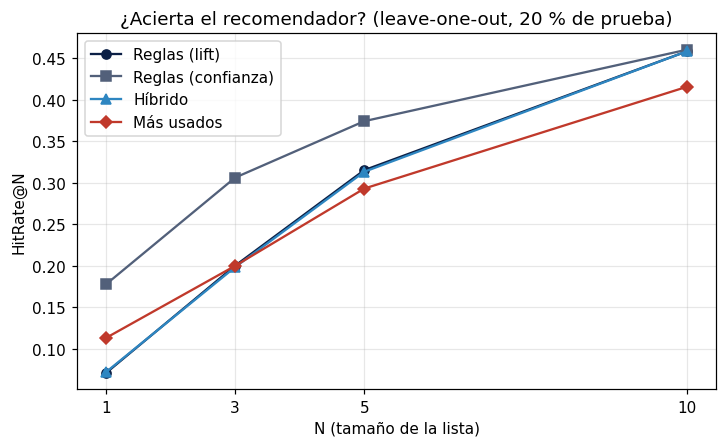

In [39]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
estilos = {"Reglas (lift)": (AZUL, "o"), "Reglas (confianza)": (GRIS, "s"),
           "Híbrido": ("#2e86c1", "^"), "Más usados": (ROJO, "D")}
for nombre, (color, marcador) in estilos.items():
    ax.plot(hitrate["N"], hitrate[nombre], marker=marcador, color=color, label=nombre)
ax.set_xticks(N_VALORES)
ax.set_xlabel("N (tamaño de la lista)")
ax.set_ylabel("HitRate@N")
ax.set_title("¿Acierta el recomendador? (leave-one-out, 20 % de prueba)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

**Discusión de la evaluación**

- **Las reglas superan a la línea base.** Ordenadas por **confianza** aciertan en el 17,8 % de los casos con una sola
  sugerencia (vs. 11,3 % de los más usados) y en el 37,4 % con 5 (vs. 29,3 %). Con N = 10 todos los sistemas basados en
  reglas llegan a ~46 % frente a 41,6 % de la línea base.
- **Lift vs. confianza.** Por lift el sistema acierta menos en las primeras posiciones (7,1 % en N = 1) porque pone
  primero asociaciones específicas, que no siempre son el ingrediente oculto. Al crecer N se empareja con la confianza.
- **Híbrido.** Casi idéntico al de lift: en el 92,6 % de los casos alguna regla activa supera lift 2, así que la
  conmutación cambia pocas listas. Sí evita sugerir por asociaciones débiles en el 7 % restante.
- **Reglas activas y cobertura.** En el **98,3 %** de las recetas de prueba se activa al menos una regla, pero los
  sistemas por reglas solo llegan a recomendar el **18 % del catálogo** (vs. 9 % de los más usados): las reglas con
  confianza ≥ 0,3 apuntan casi siempre a ingredientes comunes.
- **Lift vs. línea base en N = 3:** prácticamente empatan (20,0 % vs. 20,0 %); el lift solo supera claramente a los
  más usados desde N = 5.
- **Precisión vs. novedad.** Las 3 primeras sugerencias por confianza tienen un soporte medio de 0,28 (muy cerca de
  los más usados, 0,33); por lift bajan a 0,16. **La confianza acierta más porque recomienda lo popular; el lift
  recomienda ingredientes menos obvios** a costa de precisión. Para una app que quiere "completar la receta"
  conviene la confianza; para inspirar o hacer venta cruzada de productos menos vendidos conviene el lift.

**Cuidados al leer estos números.** (1) El ingrediente oculto siempre pertenece al catálogo de 222 ingredientes
frecuentes: los ingredientes raros nunca se ocultan, así que el HitRate real en una app sería menor. (2) El catálogo
(soporte ≥ 0,5 %) se definió con toda la muestra antes de la partición. Solo decide **qué columnas** tiene la matriz
(no usa la etiqueta oculta ni las reglas); las reglas y los populares de la evaluación sí se calculan **solo con
entrenamiento**.


## 8. Hallazgos y recomendaciones

**Hallazgos**
1. Las recetas se separan en dos mundos con poca mezcla: **salado** (sal, pimienta, ajo, cebolla, aceite de oliva) y
   **repostería** (harina, huevo, azúcar, mantequilla, polvos de hornear, vainilla).
2. Las asociaciones más fuertes son de **nicho y muy estandarizadas**: condimentos en polvo (`onion powder` →
   `garlic powder`, lift 13,6), química de horneado (`buttermilk` → `baking soda`), especias dulces y pan.
3. La **sal** (53 % de las recetas) genera reglas con confianza alta y lift ≈ 1: Fisher + Holm eliminó 32 de ellas.
4. El recomendador por reglas **supera a la línea base de populares** en HitRate@N para todo N cuando se ordena por
   confianza, y para N ≥ 5 cuando se ordena por lift.

**Acciones recomendadas**
- **App de recetas:** al armar una receta, sugerir el ingrediente faltante ordenado por **confianza** y mostrar la
  regla como motivo (*"el 80 % de las recetas con harina y levadura llevan agua"*).
- **Supermercado en línea:** venta cruzada ordenada por **lift** para destacar productos complementarios menos obvios
  (ej. mozzarella → parmesano; salsa de soya + jengibre → cebollín).
- **Arranque en frío:** para ingredientes poco frecuentes (cócteles, ingredientes étnicos) no basta el respaldo de
  populares; conviene un respaldo por categoría de receta.

**Limitaciones**
- **Asociación no es causalidad:** que dos ingredientes aparezcan juntos no significa que uno "requiera" al otro.
- **Sesgo hacia lo popular:** el respaldo y la línea base sugieren sal, pimienta y mantequilla a cualquier canasta.
- **Muestra y catálogo:** se usaron 30.000 recetas e ingredientes con soporte ≥ 0,5 %; los ingredientes raros no
  pueden recomendarse.
- **Normalización imperfecta:** el mapa de la base y nuestro diccionario unifican variantes frecuentes, pero quedan
  sinónimos sin unir (por ejemplo, `cheese` genérico y `cheddar` quedan como ítems distintos).
- **Evaluación offline optimista:** el ingrediente oculto siempre es del catálogo frecuente, y HitRate mide si se
  "adivina" lo que ya estaba en la receta, no si la sugerencia le sirve a la persona (eso requeriría un test A/B).
- **Privacidad:** solo se usan recetas e ingredientes; no se publican ids de usuarios ni reseñas.

## 9. Exportación de CSV para el dashboard

El dashboard (`app.py`, Streamlit) **no mina reglas** en cada interacción: lee estos CSV precalculados (con `@st.cache_data`).

| Archivo | Módulo del dashboard |
|---|---|
| `resumen.csv`, `populares.csv` | 1. Resumen de datos |
| `reglas.csv` | 2. Explorador de reglas y 3. Visualizaciones (dispersión, grafo y mapa de flujo) |
| `reglas_recomendador.csv`, `populares.csv` | 4. Recomendador (lift, confianza e híbrido) |
| `hitrate.csv`, `cobertura.csv` | 5. Evaluación |

In [40]:
os.makedirs("data", exist_ok=True)


def a_texto(itemset):
    # Itemset → texto "a, b" (sin llaves) para guardar en CSV
    return ", ".join(sorted(itemset))


# 1) Resumen de datos
resumen_csv = pd.DataFrame({
    "indicador": ["recetas_originales", "transacciones", "items", "densidad", "items_por_receta",
                  "reglas_minadas", "reglas_significativas", "reglas_finales", "reglas_recomendador"],
    "valor": [n_inicial, len(datos), datos.shape[1], densidad, items_por_receta.mean(),
              len(reglas), int(reglas["significativa"].sum()), len(reglas_finales), len(reglas_rec)],
})
resumen_csv.to_csv("data/resumen.csv", index=False)

# 2) Ingredientes más usados (línea base del recomendador)
populares_csv = pd.DataFrame({"ingrediente": soporte_item.index, "soporte": soporte_item.values,
                              "recetas": datos.sum().loc[soporte_item.index].values})
populares_csv.to_csv("data/populares.csv", index=False)

# 3) Reglas de la Parte 1 (todas las minadas, con marcas de significancia y redundancia)
reglas_csv = pd.DataFrame({
    "antecedente": reglas["antecedents"].apply(a_texto),
    "consecuente": reglas["consequents"].apply(a_texto),
    "soporte": reglas["support"], "confianza": reglas["confidence"], "lift": reglas["lift"],
    "leverage": reglas["leverage"], "conviccion": reglas["conviction"],
    "p_ajustado": reglas["p_ajustado"], "significativa": reglas["significativa"],
    "redundante": reglas["redundante"],
}).sort_values("lift", ascending=False)
reglas_csv["conviccion"] = reglas_csv["conviccion"].replace(np.inf, np.nan)
reglas_csv.to_csv("data/reglas.csv", index=False)

# 4) Reglas del recomendador (un consecuente, minadas con toda la muestra)
reglas_rec_csv = pd.DataFrame({
    "antecedente": reglas_rec["antecedents"].apply(a_texto), "producto": reglas_rec["producto"],
    "soporte": reglas_rec["support"], "confianza": reglas_rec["confidence"], "lift": reglas_rec["lift"],
})
reglas_rec_csv.to_csv("data/reglas_recomendador.csv", index=False)

# 5) Evaluación
hitrate.to_csv("data/hitrate.csv", index=False)
cobertura.to_csv("data/cobertura.csv", index=False)

for archivo in sorted(os.listdir("data")):
    print(f"{archivo:28s} {os.path.getsize(os.path.join('data', archivo)) / 1024:8.1f} KB")

cobertura.csv                     0.4 KB
hitrate.csv                       0.4 KB
populares.csv                     7.8 KB
reglas.csv                      130.7 KB
reglas_recomendador.csv         242.9 KB
resumen.csv                       0.2 KB


### 9.1 Armado del repositorio para GitHub

Las celdas siguientes crean la carpeta `certamen2-grupo-2/` con la estructura que pide el enunciado y la descargan
como **un solo zip**. Al descomprimirlo queda todo listo para subir a GitHub:

```
certamen2-grupo-2/
├── README.md
├── requirements.txt
├── app.py
├── .gitignore
├── ficha_base.md
├── .streamlit/config.toml
├── data/   (los 6 CSV de la sección 9)
└── Certamen2_Grupo_2.ipynb
```

Cada archivo se escribe con `%%writefile`: así el código del dashboard (`app.py`) también queda dentro del notebook
y se puede revisar aquí mismo. **Si se cambia el dashboard, hay que cambiarlo en la celda de `app.py`.**

In [41]:
# Carpeta del repositorio y copia de los CSV exportados en la sección 9
import shutil

REPO = "certamen2-grupo-2"
os.makedirs(os.path.join(REPO, ".streamlit"), exist_ok=True)
shutil.copytree("data", os.path.join(REPO, "data"), dirs_exist_ok=True)
print("CSV copiados:", sorted(os.listdir(os.path.join(REPO, "data"))))

CSV copiados: ['cobertura.csv', 'hitrate.csv', 'populares.csv', 'reglas.csv', 'reglas_recomendador.csv', 'resumen.csv']


**README** (descripción del problema, fuente de los datos, cómo ejecutar y link a la app). Recordar reemplazar `<app>` por el link real de Streamlit.

In [42]:
%%writefile certamen2-grupo-2/README.md
# ¿Qué ingrediente le falta a tu receta?

**Certamen 2 — Reglas de asociación y sistemas de recomendación**
Aprendizaje no supervisado · UDD · Docente: Danilo Gómez Correa
**Grupo 2:** Lucas Torres Baeza · María Jesús Salinas

**Dashboard publicado:** https://taller-ii-ml-ns.streamlit.app

---

## Problema

Una app de recetas o un supermercado en línea quiere ayudar a quien arma una receta o su lista de compras:
*"quienes usan estos ingredientes también usan…"*. El recomendador sugiere el ingrediente que probablemente
falta (por ejemplo, *"¿te falta la levadura?"*) y muestra la **regla** que justifica cada sugerencia.

## Datos

| | |
|---|---|
| **Base** | [Food.com Recipes and User Interactions](https://www.kaggle.com/datasets/shuyangli94/food-com-recipes-and-user-interactions) (Kaggle, `shuyangli94`) |
| **Fuente** | Majumder, B. P., Li, S., Ni, J. y McAuley, J. (2019). *Generating Personalized Recipes from Historical User Preferences*. EMNLP. |
| **Licencia** | Publicada en Kaggle por los autores; uso académico citando la fuente. Los datos crudos **no** se suben al repositorio. |
| **Transacción** | Una **receta** |
| **Ítem** | Un **ingrediente** normalizado |
| **Tamaño final** | 28.878 recetas × 222 ingredientes · 7,2 ingredientes por receta · densidad 3,2 % |

## Resultados principales

- **880 reglas** (soporte ≥ 0,01; confianza ≥ 0,5) → **848** significativas (Fisher + Holm, α = 0,01) → **785** no redundantes.
- Regla más fuerte: `{onion powder} ⇒ {garlic powder}` (confianza 0,65; lift 13,6).
- Las 32 reglas descartadas por Fisher son todas `X ⇒ {salt}` con lift ≈ 1: la sal está en el 53 % de las recetas.
- **HitRate@N** (leave-one-out, 20 % de prueba): las reglas por confianza aciertan 17,8 % con N = 1 frente a 11,3 % de los más usados, y 46,1 % vs. 41,6 % con N = 10.

## Estructura del repositorio

```
certamen2-grupo-2/
├── README.md                ← este archivo
├── requirements.txt         ← dependencias
├── app.py                   ← dashboard (Streamlit)
├── .streamlit/config.toml   ← colores del dashboard
├── ficha_base.md            ← ficha de la base (entregable 1)
├── data/                    ← CSV que exporta el notebook y lee el dashboard
│   ├── resumen.csv               indicadores de la base
│   ├── populares.csv             soporte de cada ingrediente (línea base)
│   ├── reglas.csv                reglas de la Parte 1 (con p ajustado y redundancia)
│   ├── reglas_recomendador.csv   reglas de un consecuente para el recomendador
│   ├── hitrate.csv               HitRate@1, 3, 5 y 10 por sistema
│   └── cobertura.csv             reglas activas, cobertura y popularidad
└── Certamen2_Grupo_2.ipynb  ← notebook completo (Colab)
```

## Cómo ejecutar

### Notebook (Google Colab)

1. Abrir `Certamen2_Grupo_2.ipynb` en Colab.
2. Los datos se descargan solos con `kagglehub`. Si falla, descargar `archive.zip` desde Kaggle y subirlo al panel *Archivos*.
3. *Entorno de ejecución → Ejecutar todas*. La última celda descarga `certamen2-grupo-2.zip` con **todo el
   repositorio** listo para GitHub: este README, `requirements.txt`, `app.py`, los CSV de `data/` y una copia del
   notebook ejecutado.

### Dashboard en local

```bash
pip install -r requirements.txt
streamlit run app.py
```

### Publicar en Streamlit Community Cloud

1. Entrar a [share.streamlit.io](https://share.streamlit.io) con la cuenta de GitHub.
2. *Create app* → elegir este repositorio, rama `main` y archivo `app.py`.
3. En *Advanced settings* elegir **Python 3.12** (con 3.14 la instalación de pandas se queda pegada).
4. Copiar el link público en este README y en la entrega de Canvas.

## Módulos del dashboard

| Pestaña | Contenido |
|---|---|
| Resumen | Transacciones, ingredientes, densidad, ingredientes más frecuentes y embudo de reglas |
| Explorador de reglas | Filtros de soporte, confianza y lift; Fisher y redundancia; filtro por ingrediente en antecedente o consecuente; tabla ordenable y descarga CSV |
| Visualizaciones | Dispersión soporte–confianza coloreada por lift, grafo de reglas y mapa de flujo (pyvis) |
| Recomendador | Canasta con selección múltiple; N sugerencias con regla, confianza y lift; lift, confianza o híbrido; avisa cuando usa el respaldo de populares |
| Evaluación | Tabla y gráfico de HitRate@N frente a la línea base, cobertura y precisión vs. novedad |

## Uso de inteligencia artificial

Se usó IA (Claude) como apoyo para revisar el código, construir el dashboard y redactar este README.
El código de la guía de clase se adaptó a la base, y todas las decisiones están explicadas en el notebook.


Writing certamen2-grupo-2/README.md


**Dependencias** (`requirements.txt`): las del dashboard primero, porque son las que instala Streamlit Community Cloud.

In [43]:
%%writefile certamen2-grupo-2/requirements.txt
# --- Dashboard (lo que instala Streamlit Community Cloud) ---
streamlit==1.45.1
pandas==2.2.3
numpy>=1.26
plotly==5.24.1
pyvis==0.3.2

# --- Notebook (análisis en Colab) ---
mlxtend==0.23.4
scipy>=1.11
statsmodels>=0.14
matplotlib>=3.8


Writing certamen2-grupo-2/requirements.txt


**Dashboard** (`app.py`): lee los CSV de `data/` y tiene los 5 módulos pedidos (resumen, explorador de reglas, visualizaciones, recomendador y evaluación).

In [44]:
%%writefile certamen2-grupo-2/app.py
# =============================================================================
# app.py — Dashboard del Certamen 2 (Grupo 2)
# "¿Qué ingrediente le falta a tu receta?" — Reglas de asociación sobre Food.com
#
# El dashboard NO mina reglas: lee los CSV que exporta el notebook
# (sección 9) desde la carpeta data/. Así la app es rápida y estable.
#
# Ejecutar en local:   streamlit run app.py
# =============================================================================

import os

import numpy as np
import pandas as pd
import streamlit as st
import streamlit.components.v1 as components
import plotly.express as px
from plotly.colors import sample_colorscale
from pyvis.network import Network

st.set_page_config(page_title="¿Qué le falta a tu receta?", layout="wide")

# Carpeta de los CSV: data/ (estructura del repositorio). Si los CSV quedaron sueltos junto a app.py,
# también los encuentra, así la app no se cae por cómo se subieron los archivos a GitHub.
BASE = os.path.dirname(os.path.abspath(__file__))
CARPETA = os.path.join(BASE, "data") if os.path.isdir(os.path.join(BASE, "data")) else BASE
AZUL = "#0b1f45"
GRIS = "#52607a"
ROJO = "#c0392b"

# Canastas de ejemplo (las mismas del notebook, sección 6.1)
EJEMPLOS = {
    "— elegir —": None,
    "Pan casero": ["flour", "yeast"],
    "Salteado asiático": ["soy sauce", "ginger"],
    "Pasta al pesto": ["basil", "pine nut"],
    "Carne con cebolla": ["ground beef", "onion"],
    "Cóctel (arranque en frío)": ["rum", "ice"],
}


# -----------------------------------------------------------------------------
# 1. Carga de datos
# -----------------------------------------------------------------------------
def a_conjunto(texto):
    # "flour, yeast" → frozenset({"flour", "yeast"})  (así se guardaron los itemsets en el CSV)
    return frozenset(texto.split(", "))


def texto_itemset(itemset):
    # frozenset → "{flour, yeast}" (igual que en el notebook)
    return "{" + ", ".join(sorted(itemset)) + "}"


@st.cache_data
def cargar_datos():
    # Se lee una sola vez y queda en caché mientras la app esté activa
    resumen = pd.read_csv(f"{CARPETA}/resumen.csv").set_index("indicador")["valor"]
    populares = pd.read_csv(f"{CARPETA}/populares.csv")
    hitrate = pd.read_csv(f"{CARPETA}/hitrate.csv")
    cobertura = pd.read_csv(f"{CARPETA}/cobertura.csv")

    # Reglas de la Parte 1 (minsop = 0,01; minconf = 0,5) con marcas de Fisher + Holm y redundancia
    reglas = pd.read_csv(f"{CARPETA}/reglas.csv")
    reglas["antecedents"] = reglas["antecedente"].apply(a_conjunto)
    reglas["consequents"] = reglas["consecuente"].apply(a_conjunto)
    reglas["regla"] = reglas["antecedents"].apply(texto_itemset) + " ⇒ " + reglas["consequents"].apply(texto_itemset)

    # Reglas del recomendador (un solo consecuente; minsop = 0,005; minconf = 0,3; lift > 1)
    reglas_rec = pd.read_csv(f"{CARPETA}/reglas_recomendador.csv")
    reglas_rec["antecedents"] = reglas_rec["antecedente"].apply(a_conjunto)
    reglas_rec["consequents"] = reglas_rec["producto"].apply(lambda p: frozenset([p]))
    reglas_rec = reglas_rec.rename(columns={"confianza": "confidence", "soporte": "support"})

    return resumen, populares, reglas, reglas_rec, hitrate, cobertura


resumen, populares, reglas, reglas_rec, hitrate, cobertura = cargar_datos()
mas_usados = populares["ingrediente"].tolist()                      # línea base (ordenada por soporte)
soporte_item = dict(zip(populares["ingrediente"], populares["soporte"]))


def miles(x):
    # 28878 → "28.878" (formato chileno)
    return f"{int(x):,}".replace(",", ".")


def color_lift(valor, minimo, maximo):
    # Tono de azul según el lift: más oscuro = asociación más fuerte (igual idea que en el notebook)
    proporcion = (valor - minimo) / (maximo - minimo) if maximo > minimo else 1
    return sample_colorscale("Blues", [0.35 + 0.65 * proporcion])[0]


# -----------------------------------------------------------------------------
# 2. Recomendador (mismo código que el notebook, sección 6)
# -----------------------------------------------------------------------------
def recomendar(canasta, reglas, populares, top=3, orden="lift"):
    canasta = set(canasta)

    # 1) Reglas activas: el antecedente está dentro de la canasta y el producto aún no está
    activa = np.array([antecedente <= canasta for antecedente in reglas["antecedents"]], dtype=bool)
    nueva = ~reglas["producto"].isin(canasta).values
    candidatas = reglas[activa & nueva]

    # 2) Ordenamos por el criterio elegido y dejamos una sola regla por producto (la mejor)
    desempate = "confidence" if orden == "lift" else "lift"
    candidatas = candidatas.sort_values([orden, desempate], ascending=False)
    candidatas = candidatas.drop_duplicates("producto").head(top)

    sugerencias = []
    for _, r in candidatas.iterrows():
        sugerencias.append({
            "producto": r["producto"],
            "motivo": texto_itemset(r["antecedents"]) + " ⇒ " + texto_itemset(r["consequents"]),
            "confianza": r["confidence"],
            "lift": r["lift"],
        })

    # 3) Arranque en frío o faltan sugerencias: completamos con los más usados que no estén en la canasta
    ya_sugeridos = {s["producto"] for s in sugerencias}
    for producto in populares:
        if len(sugerencias) >= top:
            break
        if producto not in canasta and producto not in ya_sugeridos:
            sugerencias.append({"producto": producto, "motivo": "más usado (respaldo)",
                                "confianza": np.nan, "lift": np.nan})

    return pd.DataFrame(sugerencias, columns=["producto", "motivo", "confianza", "lift"])


def recomendar_hibrido(canasta, reglas, populares, top=3, lift_minimo=2.0):
    # Híbrido conmutado: reglas (por lift) solo si alguna regla activa supera el lift mínimo
    canasta_set = set(canasta)
    activa = np.array([antecedente <= canasta_set for antecedente in reglas["antecedents"]], dtype=bool)
    nueva = ~reglas["producto"].isin(canasta_set).values
    lift_activas = reglas.loc[activa & nueva, "lift"]

    if len(lift_activas) > 0 and lift_activas.max() > lift_minimo:
        return recomendar(canasta, reglas, populares, top=top, orden="lift")
    sugerencias = [p for p in populares if p not in canasta_set][:top]
    return pd.DataFrame({"producto": sugerencias,
                         "motivo": f"más usado (híbrido: sin regla con lift > {lift_minimo})",
                         "confianza": np.nan, "lift": np.nan})


# -----------------------------------------------------------------------------
# 3. Grafos con pyvis (mismo diseño que el notebook, sección 5.4)
# -----------------------------------------------------------------------------
def grafo_reglas(tabla, alto=600):
    # Cuadros = ingredientes; círculos = reglas (tamaño = soporte, color = lift)
    red = Network(height=f"{alto}px", width="100%", directed=True, cdn_resources="remote")
    lift_min, lift_max = tabla["lift"].min(), tabla["lift"].max()
    soporte_max = tabla["soporte"].max()

    for i, r in tabla.reset_index(drop=True).iterrows():
        nombre = f"regla {i + 1}"
        detalle = (f"{r['regla']}\nsoporte: {r['soporte']:.3f}\n"
                   f"confianza: {r['confianza']:.3f}\nlift: {r['lift']:.2f}")
        red.add_node(nombre, label=" ", title=detalle, shape="dot",
                     size=10 + 25 * r["soporte"] / soporte_max,
                     color=color_lift(r["lift"], lift_min, lift_max))
        for item in r["antecedents"] | r["consequents"]:
            red.add_node(item, label=item, shape="box", color="#e6e9ef",
                         font={"color": AZUL, "size": 18}, title=f"soporte: {soporte_item.get(item, 0):.3f}")
        for item in r["antecedents"]:
            red.add_edge(item, nombre, color=GRIS)
        for item in r["consequents"]:
            red.add_edge(nombre, item, color=GRIS)

    red.repulsion(node_distance=140, spring_length=120)
    return red.generate_html()


def mapa_flujo(tabla, alto=600):
    # Solo reglas simples {A} ⇒ {B}: grosor = confianza, color = lift, tamaño del nodo = soporte
    red = Network(height=f"{alto}px", width="100%", directed=True, cdn_resources="remote")
    lift_min, lift_max = tabla["lift"].min(), tabla["lift"].max()

    for item in set(tabla["antecedente"]) | set(tabla["consecuente"]):
        red.add_node(item, label=item, shape="dot", color=AZUL, size=10 + 80 * soporte_item.get(item, 0),
                     font={"size": 22, "color": AZUL, "strokeWidth": 5, "strokeColor": "white"},
                     title=f"{item}\nsoporte: {soporte_item.get(item, 0):.3f}")
    for _, r in tabla.iterrows():
        red.add_edge(r["antecedente"], r["consecuente"], width=1 + 8 * r["confianza"],
                     color=color_lift(r["lift"], lift_min, lift_max),
                     title=f"{r['regla']}\nconfianza: {r['confianza']:.3f}\nlift: {r['lift']:.2f}")

    red.barnes_hut(gravity=-9000, spring_length=160)
    return red.generate_html()


# -----------------------------------------------------------------------------
# 4. Barra lateral: filtros de reglas (aplican al Explorador y a las Visualizaciones)
# -----------------------------------------------------------------------------
st.sidebar.title("¿Qué le falta a tu receta?")
st.sidebar.caption("Análisis de canasta sobre recetas de Food.com · Grupo 2")
st.sidebar.header("Filtros de reglas")
st.sidebar.caption("Aplican a las pestañas **Explorador** y **Visualizaciones**. Las reglas se minaron "
                   "con soporte ≥ 0,01 y confianza ≥ 0,5, por eso los controles parten ahí.")

min_soporte = st.sidebar.slider("Soporte mínimo", 0.010, float(round(reglas["soporte"].max(), 3)),
                                0.010, step=0.001, format="%.3f")
min_confianza = st.sidebar.slider("Confianza mínima", 0.50, 1.00, 0.50, step=0.01)
min_lift = st.sidebar.slider("Lift mínimo", 0.9, float(np.ceil(reglas["lift"].max())), 0.9, step=0.1)
solo_signif = st.sidebar.checkbox("Solo significativas (Fisher + Holm)", value=True)
sin_redund = st.sidebar.checkbox("Excluir redundantes", value=True)

items_en_reglas = sorted(set().union(*reglas["antecedents"]) | set().union(*reglas["consequents"]))
item_filtro = st.sidebar.selectbox("Filtrar por ingrediente", ["(todos)"] + items_en_reglas)
donde = st.sidebar.radio("¿Dónde debe aparecer?", ["Antecedente", "Consecuente", "Cualquiera"], horizontal=True)

# Aplicamos los filtros
filtro = ((reglas["soporte"] >= min_soporte) & (reglas["confianza"] >= min_confianza) &
          (reglas["lift"] >= min_lift))
if solo_signif:
    filtro &= reglas["significativa"]
if sin_redund:
    filtro &= ~reglas["redundante"]
if item_filtro != "(todos)":
    en_ant = reglas["antecedents"].apply(lambda x: item_filtro in x)
    en_con = reglas["consequents"].apply(lambda x: item_filtro in x)
    filtro &= {"Antecedente": en_ant, "Consecuente": en_con, "Cualquiera": en_ant | en_con}[donde]

filtradas = reglas[filtro].sort_values("lift", ascending=False).reset_index(drop=True)
st.sidebar.metric("Reglas que cumplen los filtros", f"{len(filtradas)} de {len(reglas)}")


# -----------------------------------------------------------------------------
# 5. Pestañas
# -----------------------------------------------------------------------------
st.title("¿Qué ingrediente le falta a tu receta?")
st.markdown("Reglas de asociación y recomendador *“quienes usan estos ingredientes también usan…”* "
            "sobre recetas de **Food.com**. **Transacción** = una receta · **Ítem** = un ingrediente normalizado.")

tab_resumen, tab_explorador, tab_visual, tab_rec, tab_eval = st.tabs(
    ["Resumen", "Explorador de reglas", "Visualizaciones", "Recomendador", "Evaluación"])

# ---------------------------- 5.1 Resumen de datos ---------------------------
with tab_resumen:
    c1, c2, c3, c4, c5, c6 = st.columns(6)
    c1.metric("Recetas originales", miles(resumen["recetas_originales"]))
    c2.metric("Transacciones (muestra)", miles(resumen["transacciones"]))
    c3.metric("Ingredientes", miles(resumen["items"]))
    c4.metric("Densidad", f"{resumen['densidad']:.1%}".replace(".", ","))
    c5.metric("Ingredientes por receta", f"{resumen['items_por_receta']:.1f}".replace(".", ","))
    c6.metric("Reglas finales", miles(resumen["reglas_finales"]))

    st.caption("Muestra aleatoria de 30.000 recetas (semilla 42) e ingredientes con soporte ≥ 0,5 %. "
               "Densidad = proporción de unos en la matriz receta × ingrediente.")

    izq, der = st.columns([3, 2])
    with izq:
        top_n = st.slider("¿Cuántos ingredientes mostrar?", 10, 40, 20, step=5)
        top = populares.head(top_n).sort_values("soporte")
        fig = px.bar(top, x="soporte", y="ingrediente", orientation="h", hover_data={"recetas": True},
                     color_discrete_sequence=[AZUL], height=28 * top_n + 80,
                     title=f"Los {top_n} ingredientes más frecuentes")
        fig.update_layout(yaxis_title=None, xaxis_tickformat=".0%")
        st.plotly_chart(fig, use_container_width=True)
    with der:
        st.subheader("De 880 reglas a 785")
        embudo = pd.DataFrame({
            "etapa": ["Minadas (sop ≥ 0,01; conf ≥ 0,5)", "Significativas (Fisher + Holm)",
                      "Significativas y no redundantes"],
            "reglas": [resumen["reglas_minadas"], resumen["reglas_significativas"], resumen["reglas_finales"]],
        })
        fig = px.funnel(embudo, x="reglas", y="etapa", color_discrete_sequence=[AZUL], height=300)
        fig.update_layout(yaxis_title=None)
        st.plotly_chart(fig, use_container_width=True)
        st.markdown("- **Cola larga:** `salt` está en el 53 % de las recetas; la mayoría de los ingredientes, en menos del 2 %.\n"
                    "- Las 32 reglas que no pasan Fisher + Holm son todas `X ⇒ {salt}` con lift ≈ 1.\n"
                    "- Las asociaciones más fuertes son de repostería y condimentos: `{onion powder} ⇒ {garlic powder}` (lift 13,6).")

# ---------------------------- 5.2 Explorador de reglas -----------------------
with tab_explorador:
    st.subheader(f"{len(filtradas)} reglas con los filtros actuales")
    st.caption("Mueve los filtros de la barra lateral. Haz clic en el encabezado de una columna para ordenar.")

    orden_tabla = st.selectbox("Ordenar por", ["lift", "confianza", "soporte", "leverage", "conviccion"])
    columnas = ["regla", "soporte", "confianza", "lift", "leverage", "conviccion",
                "p_ajustado", "significativa", "redundante"]
    tabla = filtradas[columnas].sort_values(orden_tabla, ascending=False).reset_index(drop=True)

    st.dataframe(
        tabla, hide_index=True, use_container_width=True, height=520,
        column_config={
            "regla": st.column_config.TextColumn("regla", width="large"),
            "soporte": st.column_config.NumberColumn(format="%.4f"),
            "confianza": st.column_config.NumberColumn(format="%.3f"),
            "lift": st.column_config.NumberColumn(format="%.2f"),
            "leverage": st.column_config.NumberColumn(format="%.4f"),
            "conviccion": st.column_config.NumberColumn("convicción", format="%.2f"),
            "p_ajustado": st.column_config.NumberColumn("p ajustado (Holm)", format="%.1e"),
        },
    )
    st.download_button("Descargar estas reglas (CSV)", tabla.to_csv(index=False).encode("utf-8"),
                       file_name="reglas_filtradas.csv", mime="text/csv")

# ---------------------------- 5.3 Visualizaciones ----------------------------
with tab_visual:
    if filtradas.empty:
        st.warning("Ninguna regla cumple los filtros. Relaja los filtros de la barra lateral.")
    else:
        fig = px.scatter(filtradas, x="soporte", y="confianza", color="lift", hover_name="regla",
                         hover_data={"soporte": ":.4f", "confianza": ":.3f", "lift": ":.2f"},
                         color_continuous_scale="Blues", height=480,
                         title=f"Soporte vs. confianza de {len(filtradas)} reglas (color = lift)")
        fig.update_traces(marker=dict(size=8, line=dict(width=0.3, color="white")))
        st.plotly_chart(fig, use_container_width=True)
        st.caption("Las reglas de mayor lift (azul oscuro) tienen soporte bajo: las asociaciones fuertes son de nicho.")

        st.divider()
        tipo = st.radio("Tipo de grafo", ["Grafo de reglas", "Mapa de flujo ingrediente → ingrediente"],
                        horizontal=True)
        k = st.slider("Reglas a mostrar (las de mayor lift)", 5, 60, 30, step=5)

        if tipo == "Grafo de reglas":
            seleccion = filtradas.head(k)
            st.caption("Cuadros: ingredientes · círculos: reglas (tamaño = soporte, color = lift). "
                       "Pasa el mouse sobre un círculo para ver la regla.")
            components.html(grafo_reglas(seleccion), height=620)
        else:
            simples = filtradas[(filtradas["antecedents"].apply(len) == 1) &
                                (filtradas["consequents"].apply(len) == 1)].head(k)
            if simples.empty:
                st.info("Con estos filtros no hay reglas simples {A} ⇒ {B}.")
            else:
                st.caption(f"{len(simples)} reglas simples. Grosor = confianza · color = lift · "
                           "tamaño del nodo = soporte.")
                components.html(mapa_flujo(simples), height=620)

# ---------------------------- 5.4 Recomendador -------------------------------
with tab_rec:
    st.subheader("Arma tu canasta y recibe sugerencias con su motivo")

    # Canasta inicial y botón para cargar ejemplos
    if "canasta" not in st.session_state:
        st.session_state["canasta"] = ["flour", "yeast"]

    def cargar_ejemplo():
        elegido = EJEMPLOS[st.session_state["ejemplo"]]
        if elegido is not None:
            st.session_state["canasta"] = elegido

    st.selectbox("Cargar una canasta de ejemplo", list(EJEMPLOS), key="ejemplo", on_change=cargar_ejemplo)
    canasta = st.multiselect("Ingredientes que ya tienes (selección múltiple)", sorted(mas_usados), key="canasta")

    c1, c2, c3 = st.columns(3)
    top_n_rec = c1.slider("N° de sugerencias (N)", 1, 10, 5)
    criterio = c2.radio("Criterio", ["Reglas por lift", "Reglas por confianza", "Híbrido conmutado"])
    lift_minimo = c3.slider("Lift mínimo del híbrido", 1.0, 5.0, 2.0, step=0.5,
                            disabled=(criterio != "Híbrido conmutado"))

    if len(canasta) == 0:
        st.info("Agrega al menos un ingrediente. Sin canasta, el sistema solo puede sugerir los más usados.")

    if criterio == "Reglas por lift":
        sugerencias = recomendar(canasta, reglas_rec, mas_usados, top=top_n_rec, orden="lift")
    elif criterio == "Reglas por confianza":
        sugerencias = recomendar(canasta, reglas_rec, mas_usados, top=top_n_rec, orden="confidence")
    else:
        sugerencias = recomendar_hibrido(canasta, reglas_rec, mas_usados, top=top_n_rec, lift_minimo=lift_minimo)

    # ¿Cuántas reglas se activan con esta canasta?
    activa = np.array([a <= set(canasta) for a in reglas_rec["antecedents"]], dtype=bool)
    activas = reglas_rec[activa & ~reglas_rec["producto"].isin(canasta).values]
    sugerencias["origen"] = np.where(sugerencias["motivo"].str.startswith("más usado"),
                                     "respaldo: más usados", "regla")

    st.dataframe(sugerencias.rename(columns={"motivo": "motivo (regla)"}), hide_index=True,
                 use_container_width=True,
                 column_config={"confianza": st.column_config.NumberColumn(format="%.3f"),
                                "lift": st.column_config.NumberColumn(format="%.2f")})

    n_respaldo = (sugerencias["origen"] != "regla").sum()
    if len(activas) == 0 and len(canasta) > 0:
        st.warning(f"**Arranque en frío:** ninguna regla se activa con esta canasta. "
                   f"Las {n_respaldo} sugerencias vienen del respaldo de los más usados.")
    elif criterio == "Híbrido conmutado" and n_respaldo == len(sugerencias) and len(canasta) > 0:
        st.warning(f"**Híbrido:** se activan {len(activas)} reglas, pero ninguna supera lift {lift_minimo}. "
                   "Se usan los más usados en vez de una asociación débil.")
    elif n_respaldo > 0:
        st.info(f"Se activan {len(activas)} reglas, pero solo alcanzan para {len(sugerencias) - n_respaldo} "
                f"productos distintos. Las otras {n_respaldo} posiciones se completan con los más usados.")
    else:
        st.success(f"Se activan {len(activas)} reglas. Todas las sugerencias vienen de una regla.")

    st.caption(f"Reglas de un solo consecuente minadas con soporte ≥ 0,005, confianza ≥ 0,3 y lift > 1 "
               f"({miles(len(reglas_rec))} reglas). Los ingredientes de la canasta nunca se recomiendan.")

# ---------------------------- 5.5 Evaluación ---------------------------------
with tab_eval:
    st.subheader("HitRate@N: ¿el ingrediente oculto aparece entre las N sugerencias?")
    st.caption("Partición 80/20 con semilla 42. Reglas minadas solo con entrenamiento (23.102 recetas). "
               "A cada una de las 5.776 recetas de prueba se le oculta un ingrediente al azar (leave-one-out).")

    izq, der = st.columns([3, 2])
    with izq:
        largo = hitrate.melt(id_vars="N", var_name="sistema", value_name="HitRate")
        fig = px.line(largo, x="N", y="HitRate", color="sistema", markers=True, height=420,
                      color_discrete_map={"Reglas (lift)": AZUL, "Reglas (confianza)": GRIS,
                                          "Híbrido": "#2e86c1", "Más usados": ROJO})
        fig.update_layout(xaxis=dict(tickmode="array", tickvals=hitrate["N"].tolist()),
                          yaxis_tickformat=".0%", legend_title=None)
        st.plotly_chart(fig, use_container_width=True)
    with der:
        tabla_hr = hitrate.set_index("N").map(lambda v: f"{v:.1%}".replace(".", ","))
        st.dataframe(tabla_hr, use_container_width=True)

    st.subheader("Reglas activas, cobertura y novedad")
    tabla_cob = cobertura.copy()
    for col in tabla_cob.columns[1:3]:
        tabla_cob[col] = tabla_cob[col].map(lambda v: f"{v:.1%}".replace(".", ","))
    tabla_cob[tabla_cob.columns[3]] = tabla_cob[tabla_cob.columns[3]].map(lambda v: f"{v:.3f}".replace(".", ","))
    st.dataframe(tabla_cob, hide_index=True, use_container_width=True)

    st.markdown(
        "- **Las reglas superan a la línea base:** por confianza, HitRate@1 = 17,8 % vs. 11,3 % de los más usados.\n"
        "- **Precisión vs. novedad:** la confianza acierta más porque sugiere ingredientes populares "
        "(soporte medio del top 3 = 0,28); el lift sugiere ingredientes menos obvios (0,16) y acierta menos en N = 1.\n"
        "- **Cobertura:** los sistemas por reglas solo llegan a recomendar el 18 % del catálogo "
        "(40 de 222 ingredientes) en su top 10; los más usados, el 9 %.")

st.divider()
st.caption("Datos: *Food.com Recipes and User Interactions* (Kaggle, shuyangli94; Majumder et al., 2019). "
           "Grupo 2 — Lucas Torres Baeza · María Jesús Salinas · Aprendizaje no supervisado, UDD.")


Writing certamen2-grupo-2/app.py


**Archivos de apoyo**: `.gitignore` (deja fuera los datos crudos de Kaggle, que pesan ~290 MB), tema del dashboard (`.streamlit/config.toml`: fondo blanco y azul marino) y ficha de la base.

In [45]:
%%writefile certamen2-grupo-2/.gitignore
# Datos crudos de Kaggle (pesan ~290 MB: superan el límite de GitHub)
data_raw/
archive.zip
*.pkl
RAW_*.csv

# Python / Jupyter
__pycache__/
.ipynb_checkpoints/
.venv/
_respaldo/


Writing certamen2-grupo-2/.gitignore


In [46]:
%%writefile certamen2-grupo-2/.streamlit/config.toml
[theme]
base = "light"
primaryColor = "#0b1f45"
backgroundColor = "#ffffff"
secondaryBackgroundColor = "#f4f6f9"
textColor = "#1a2233"
font = "sans serif"


Writing certamen2-grupo-2/.streamlit/config.toml


In [47]:
%%writefile certamen2-grupo-2/ficha_base.md
# Ficha de la base — Grupo 2

| | |
|---|---|
| **Nombre** | Food.com Recipes and User Interactions |
| **Enlace** | https://www.kaggle.com/datasets/shuyangli94/food-com-recipes-and-user-interactions |
| **Origen** | Recetas publicadas en Food.com entre 2000 y 2018 (Majumder et al., 2019, EMNLP) |
| **Archivos usados** | `RAW_recipes.csv` (231.637 recetas) e `ingr_map.pkl` (normalización de ingredientes) |
| **Transacción** | Una **receta** |
| **Ítem** | Un **ingrediente** con su nombre normalizado (`garlic clove` → `garlic`, `all-purpose flour` → `flour`) |
| **N° de transacciones** | 28.878 recetas (muestra aleatoria de 30.000 con semilla 42, después de la limpieza y de exigir ≥ 2 ingredientes) |
| **N° de ítems** | 222 ingredientes (soporte ≥ 0,5 % en la muestra) |
| **Ítems por transacción** | 7,2 en promedio (mediana 7) |
| **Uso del recomendador** | Sugerir el ingrediente que falta al armar una receta o una lista de compras (venta cruzada en un supermercado en línea), mostrando la regla que lo justifica |


Writing certamen2-grupo-2/ficha_base.md


**Copia del notebook y descarga del zip.** En Colab se guarda una copia del notebook tal como está (con sus
resultados) dentro del repositorio. Por eso esta celda debe ejecutarse **al final**, después de *Ejecutar todas*.

In [ ]:
import json

# 1) Copia del notebook con sus resultados
destino_nb = os.path.join(REPO, "Certamen2_Grupo_2.ipynb")
if "google.colab" in sys.modules:
    from google.colab import _message
    notebook = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
    with open(destino_nb, "w", encoding="utf-8") as f:
        json.dump(notebook, f, ensure_ascii=False, indent=1)
elif os.path.exists("Certamen2_Grupo_2.ipynb"):
    shutil.copy("Certamen2_Grupo_2.ipynb", destino_nb)      # fuera de Colab: copia del archivo local

# 2) Revisión: lista de archivos del repositorio con su tamaño
for carpeta, _, archivos in os.walk(REPO):
    for archivo in sorted(archivos):
        ruta_archivo = os.path.join(carpeta, archivo)
        print(f"{ruta_archivo:55s} {os.path.getsize(ruta_archivo) / 1024:8.1f} KB")

# 3) Zip con la carpeta completa (al descomprimir aparece certamen2-grupo-2/)
shutil.make_archive(REPO, "zip", root_dir=".", base_dir=REPO)
print(f"\nListo: {REPO}.zip")
if "google.colab" in sys.modules:
    from google.colab import files
    files.download(f"{REPO}.zip")

### 9.2 Cómo subir el zip a GitHub sin perder las carpetas

1. Descomprimir `certamen2-grupo-2.zip` y **entrar** a la carpeta `certamen2-grupo-2/`.
2. Seleccionar todo su contenido (`Ctrl + A`): archivos **y** las carpetas `data` y `.streamlit`.
3. En GitHub: *Add file → Upload files* y **arrastrar** la selección a la página. Arrastrando, GitHub conserva las
   carpetas; con el botón *choose your files* solo se pueden elegir archivos sueltos y las carpetas se pierden.
4. Antes de *Commit changes*, revisar que la lista muestre `data/resumen.csv` y `.streamlit/config.toml`.
5. En Streamlit Community Cloud la app debe estar creada con **Python 3.12** (*Advanced settings*).
